# Earthquake Damage Prediction

## Project Overview

Earthquakes can cause significant damage to buildings, infrastructure, and human lives. The extent of damage experienced by a building depends on several factors, including its structural characteristics, construction materials, geographical location, age, and design.

This project focuses on analyzing building characteristics and developing machine learning models to predict the level of damage sustained by buildings during an earthquake.

The dataset contains building-level information from the region affected by the Gorkha earthquake. The objective is to identify patterns associated with different damage levels and develop a predictive model that can help assess building vulnerability.

## Problem Statement

The objective of this project is to perform comprehensive data analysis on earthquake-related building data and develop a machine learning model to predict the ordinal target variable `damage_grade`.

The target variable represents the extent of earthquake damage sustained by a building:

- **Grade 1:** Low damage
- **Grade 2:** Medium damage
- **Grade 3:** Almost complete destruction

Additionally, the project aims to identify important factors influencing building damage and provide data-driven recommendations to support earthquake preparedness, structural safety, and damage mitigation.

## Project Objectives

1. Perform comprehensive exploratory data analysis to understand the dataset.
2. Identify patterns and relationships between building characteristics and earthquake damage.
3. Clean and preprocess the data for machine learning.
4. Develop multiple classification models to predict `damage_grade`.
5. Evaluate and compare model performance using appropriate metrics.
6. Select the most suitable model for potential production use.
7. Identify significant features influencing building damage.
8. Analyze challenges encountered during the project and document the techniques used to address them.
9. Provide actionable recommendations to reduce earthquake-related building damage.

## Dataset Description

The dataset contains information about buildings located in the region affected by the Gorkha earthquake.

Each record represents an individual building. The dataset includes information related to:

- Geographical location
- Building structure and dimensions
- Construction materials
- Foundation and roof types
- Building age
- Legal ownership status
- Building usage
- Number of families residing in the building
- Earthquake damage grade

The dataset consists of building feature information and corresponding target labels stored in separate files.

## Target Variable

The target variable is `damage_grade`, an ordinal categorical variable with three classes:

| Damage Grade | Description |
|---|---|
| 1 | Low damage |
| 2 | Medium damage |
| 3 | Almost complete destruction |

## Project Workflow

1. Data Loading and Understanding
2. Data Cleaning and Quality Assessment
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Data Preprocessing
6. Train-Test Split
7. Model Building
8. Model Evaluation
9. Model Comparison
10. Final Model Selection
11. Feature Importance Analysis
12. Recommendations for Damage Mitigation
13. Challenges Faced and Solutions
14. Final Conclusion

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualization settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# 2. Data Loading

from pathlib import Path

# Locate the project directory
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent
]

project_root = next(
    (
        root for root in candidate_roots
        if (root / "data" / "raw").is_dir()
    ),
    None
)

# Fallback to the local project directory if necessary
if project_root is None:
    project_root = Path(
        r"C:\Users\Rakshitha\OneDrive\Desktop\Earthquake_Damage_Prediction"
    )

# Define the raw data directory
data_path = project_root / "data" / "raw"

# Define dataset file paths
train_values_path = data_path / "train_values.csv"
train_labels_path = data_path / "train_labels.csv"

# Verify dataset files
if not train_values_path.exists():
    raise FileNotFoundError(f"File not found: {train_values_path}")

if not train_labels_path.exists():
    raise FileNotFoundError(f"File not found: {train_labels_path}")

# Load datasets
train_values = pd.read_csv(train_values_path)
train_labels = pd.read_csv(train_labels_path)

# Display dataset information
print("Datasets loaded successfully!")
print("Project Directory:", project_root)
print("Train Values Shape:", train_values.shape)
print("Train Labels Shape:", train_labels.shape)

Datasets loaded successfully!
Project Directory: C:\Users\Rakshitha\OneDrive\Desktop\Earthquake_Damage_Prediction
Train Values Shape: (260601, 39)
Train Labels Shape: (260601, 2)


In [3]:
# Check the dimensions of both datasets

print("Train Values Shape:", train_values.shape)
print("Train Labels Shape:", train_labels.shape)

Train Values Shape: (260601, 39)
Train Labels Shape: (260601, 2)


In [4]:
train_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


In [5]:
train_labels.head()

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


# 3. Dataset Integration and Initial Understanding

## 3.1 Verification of Building IDs

In [6]:
# Check the number of unique building IDs
print("Unique IDs in train_values:", train_values['building_id'].nunique())
print("Unique IDs in train_labels:", train_labels['building_id'].nunique())

# Check whether building IDs match between datasets
print("IDs present only in train_values:",
      len(set(train_values['building_id']) - set(train_labels['building_id'])))

print("IDs present only in train_labels:",
      len(set(train_labels['building_id']) - set(train_values['building_id'])))

Unique IDs in train_values: 260601
Unique IDs in train_labels: 260601
IDs present only in train_values: 0
IDs present only in train_labels: 0


In [7]:
# Merge building features with target labels using building_id
data = pd.merge(
    train_values,
    train_labels,
    on='building_id',
    how='inner',
    validate='one_to_one'
)

print("Datasets merged successfully!")

Datasets merged successfully!


In [8]:
# Check the dimensions of the merged dataset
print("Merged Dataset Shape:", data.shape)

Merged Dataset Shape: (260601, 40)


In [9]:
# Display the first five records of the merged dataset
data.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


## 3.2 Dataset Dimensions

In [10]:
# Check the number of rows and columns
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])

Number of Rows: 260601
Number of Columns: 40


## 3.3 Dataset Information

In [11]:
# Display dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

## 3.4 Statistical Summary

In [12]:
# Generate descriptive statistics for numerical columns
data.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00,260601.00
mean,525675.48,13.90,701.07,6257.88,2.13,26.54,8.02,5.43,0.09,0.76,0.03,0.02,0.07,0.08,0.25,0.09,0.04,0.02,0.01,0.98,0.11,0.06,0.03,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.01,2.24
std,304545.00,8.03,412.71,3646.37,0.73,73.57,4.39,1.92,0.28,0.43,0.18,0.13,0.25,0.26,0.44,0.28,0.20,0.12,0.12,0.42,0.32,0.25,0.18,0.09,0.03,0.02,0.03,0.01,0.01,0.01,0.07,0.61
min,4.00,0.00,0.00,0.00,1.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,261190.00,7.00,350.00,3073.00,2.00,10.00,5.00,4.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00
50%,525757.00,12.00,702.00,6270.00,2.00,15.00,7.00,5.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00
75%,789762.00,21.00,1050.00,9412.00,2.00,30.00,9.00,6.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00
max,1052934.00,30.00,1427.00,12567.00,9.00,995.00,100.00,32.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,9.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,3.00


## 3.5 Feature Names

In [13]:
# Display all column names
data.columns.tolist()

['building_id',
 'geo_level_1_id',
 'geo_level_2_id',
 'geo_level_3_id',
 'count_floors_pre_eq',
 'age',
 'area_percentage',
 'height_percentage',
 'land_surface_condition',
 'foundation_type',
 'roof_type',
 'ground_floor_type',
 'other_floor_type',
 'position',
 'plan_configuration',
 'has_superstructure_adobe_mud',
 'has_superstructure_mud_mortar_stone',
 'has_superstructure_stone_flag',
 'has_superstructure_cement_mortar_stone',
 'has_superstructure_mud_mortar_brick',
 'has_superstructure_cement_mortar_brick',
 'has_superstructure_timber',
 'has_superstructure_bamboo',
 'has_superstructure_rc_non_engineered',
 'has_superstructure_rc_engineered',
 'has_superstructure_other',
 'legal_ownership_status',
 'count_families',
 'has_secondary_use',
 'has_secondary_use_agriculture',
 'has_secondary_use_hotel',
 'has_secondary_use_rental',
 'has_secondary_use_institution',
 'has_secondary_use_school',
 'has_secondary_use_industry',
 'has_secondary_use_health_post',
 'has_secondary_use_gov_of

In [14]:
# Check missing values in each column
missing_values = data.isnull().sum()

# Display columns with missing values
missing_values[missing_values > 0]

Series([], dtype: int64)

In [15]:
# Calculate missing values percentage
missing_percentage = (data.isnull().sum() / len(data)) * 100

# Display columns with missing values
missing_percentage[missing_percentage > 0].sort_values(ascending=False)

Series([], dtype: float64)

In [16]:
# Check duplicate rows
print("Number of duplicate rows:", data.duplicated().sum())

Number of duplicate rows: 0


In [17]:
# Check duplicate building IDs
print("Duplicate building IDs:", data['building_id'].duplicated().sum())

Duplicate building IDs: 0


# 4. Exploratory Data Analysis (EDA)

## 4.1 Target Variable Distribution

In [18]:
# Distribution of damage grades
damage_counts = data['damage_grade'].value_counts().sort_index()

print("Damage Grade Distribution:")
print(damage_counts)

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [19]:
# Calculate percentage distribution of damage grades
damage_percentage = data['damage_grade'].value_counts(normalize=True).sort_index() * 100

print("Damage Grade Percentage:")
print(damage_percentage.round(2))

Damage Grade Percentage:
damage_grade
1    9.64
2   56.89
3   33.47
Name: proportion, dtype: float64


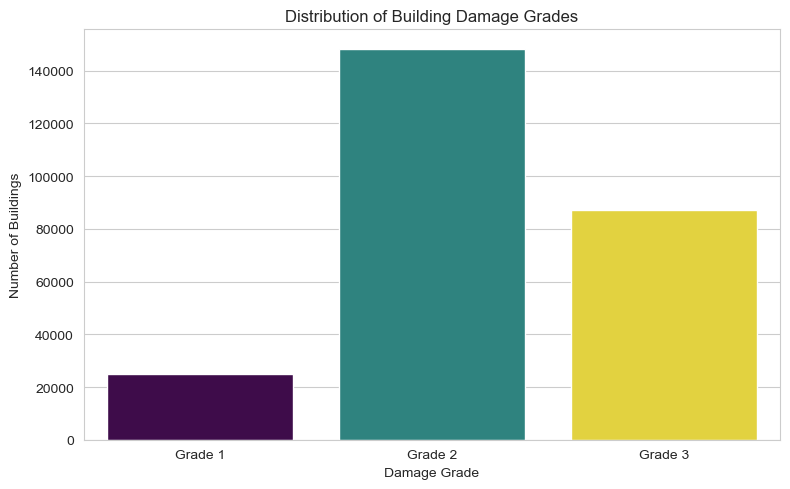

In [20]:
# Visualize damage grade distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=data, x='damage_grade', hue='damage_grade', palette='viridis', legend=False)

plt.title('Distribution of Building Damage Grades')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Buildings')
plt.xticks([0, 1, 2], ['Grade 1', 'Grade 2', 'Grade 3'])

plt.tight_layout()
plt.show()

## 4.2 Numerical Feature Analysis

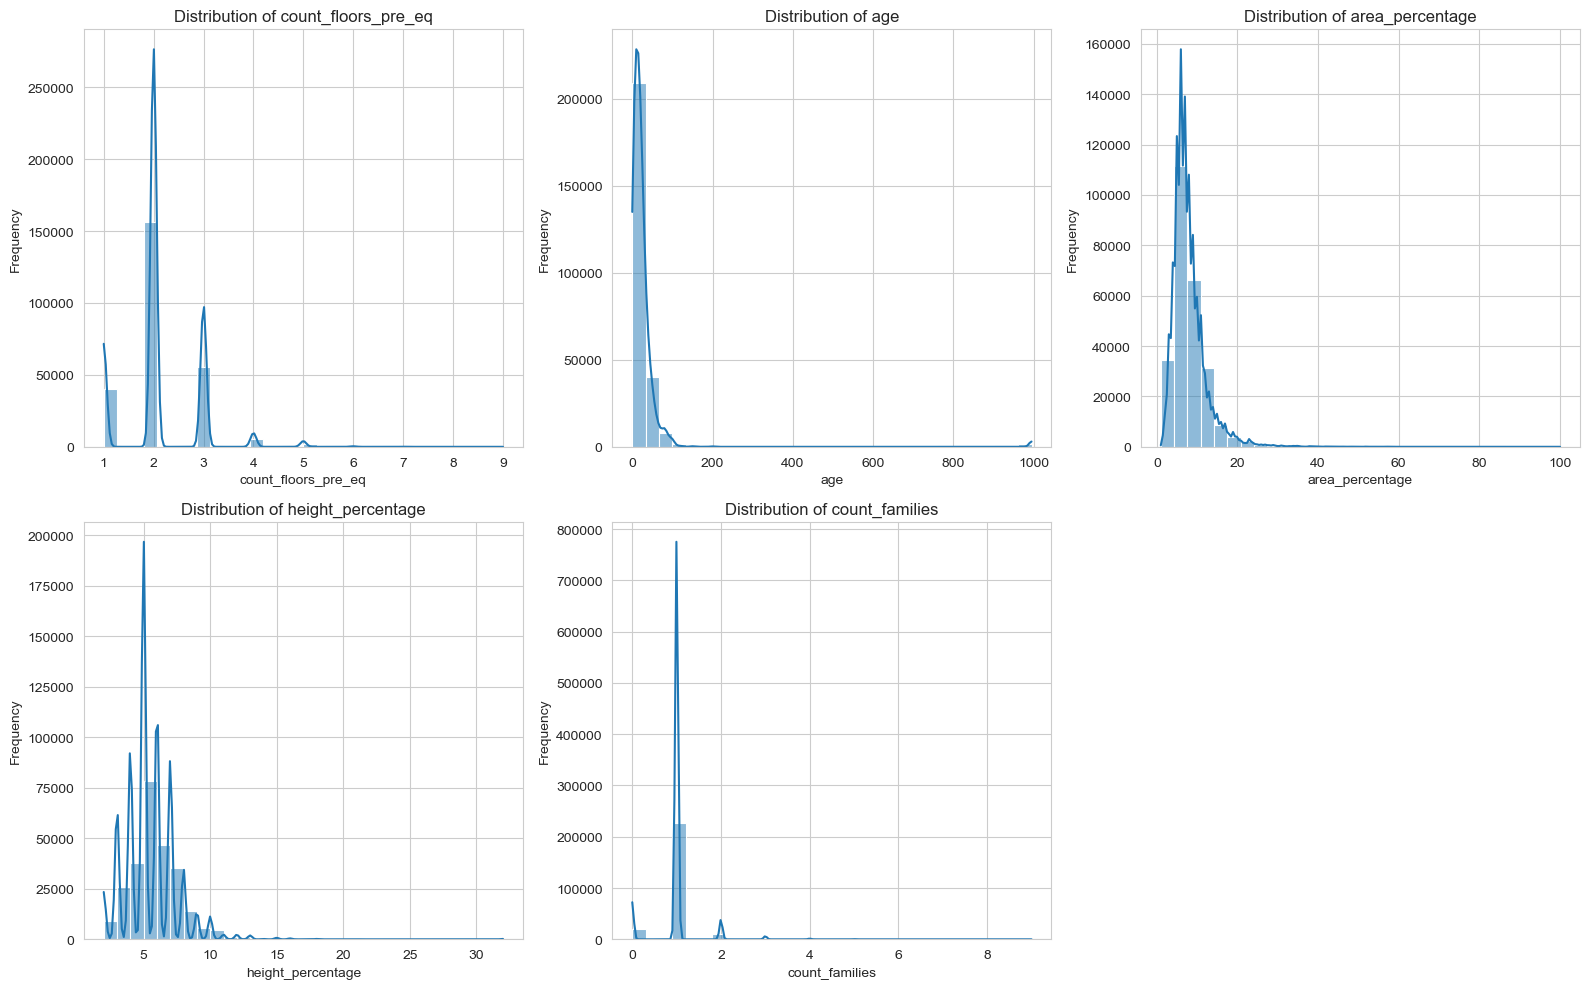

In [21]:
# Select numerical building characteristics
numerical_features = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families'
]

# Plot distributions of numerical features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.histplot(data=data, x=feature, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

# Remove the unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 4.3 Categorical Feature Analysis

In [22]:
# Select categorical features
categorical_features = [
    'land_surface_condition',
    'foundation_type',
    'roof_type',
    'ground_floor_type',
    'other_floor_type',
    'position',
    'plan_configuration',
    'legal_ownership_status'
]

print("Number of categorical features:", len(categorical_features))

Number of categorical features: 8


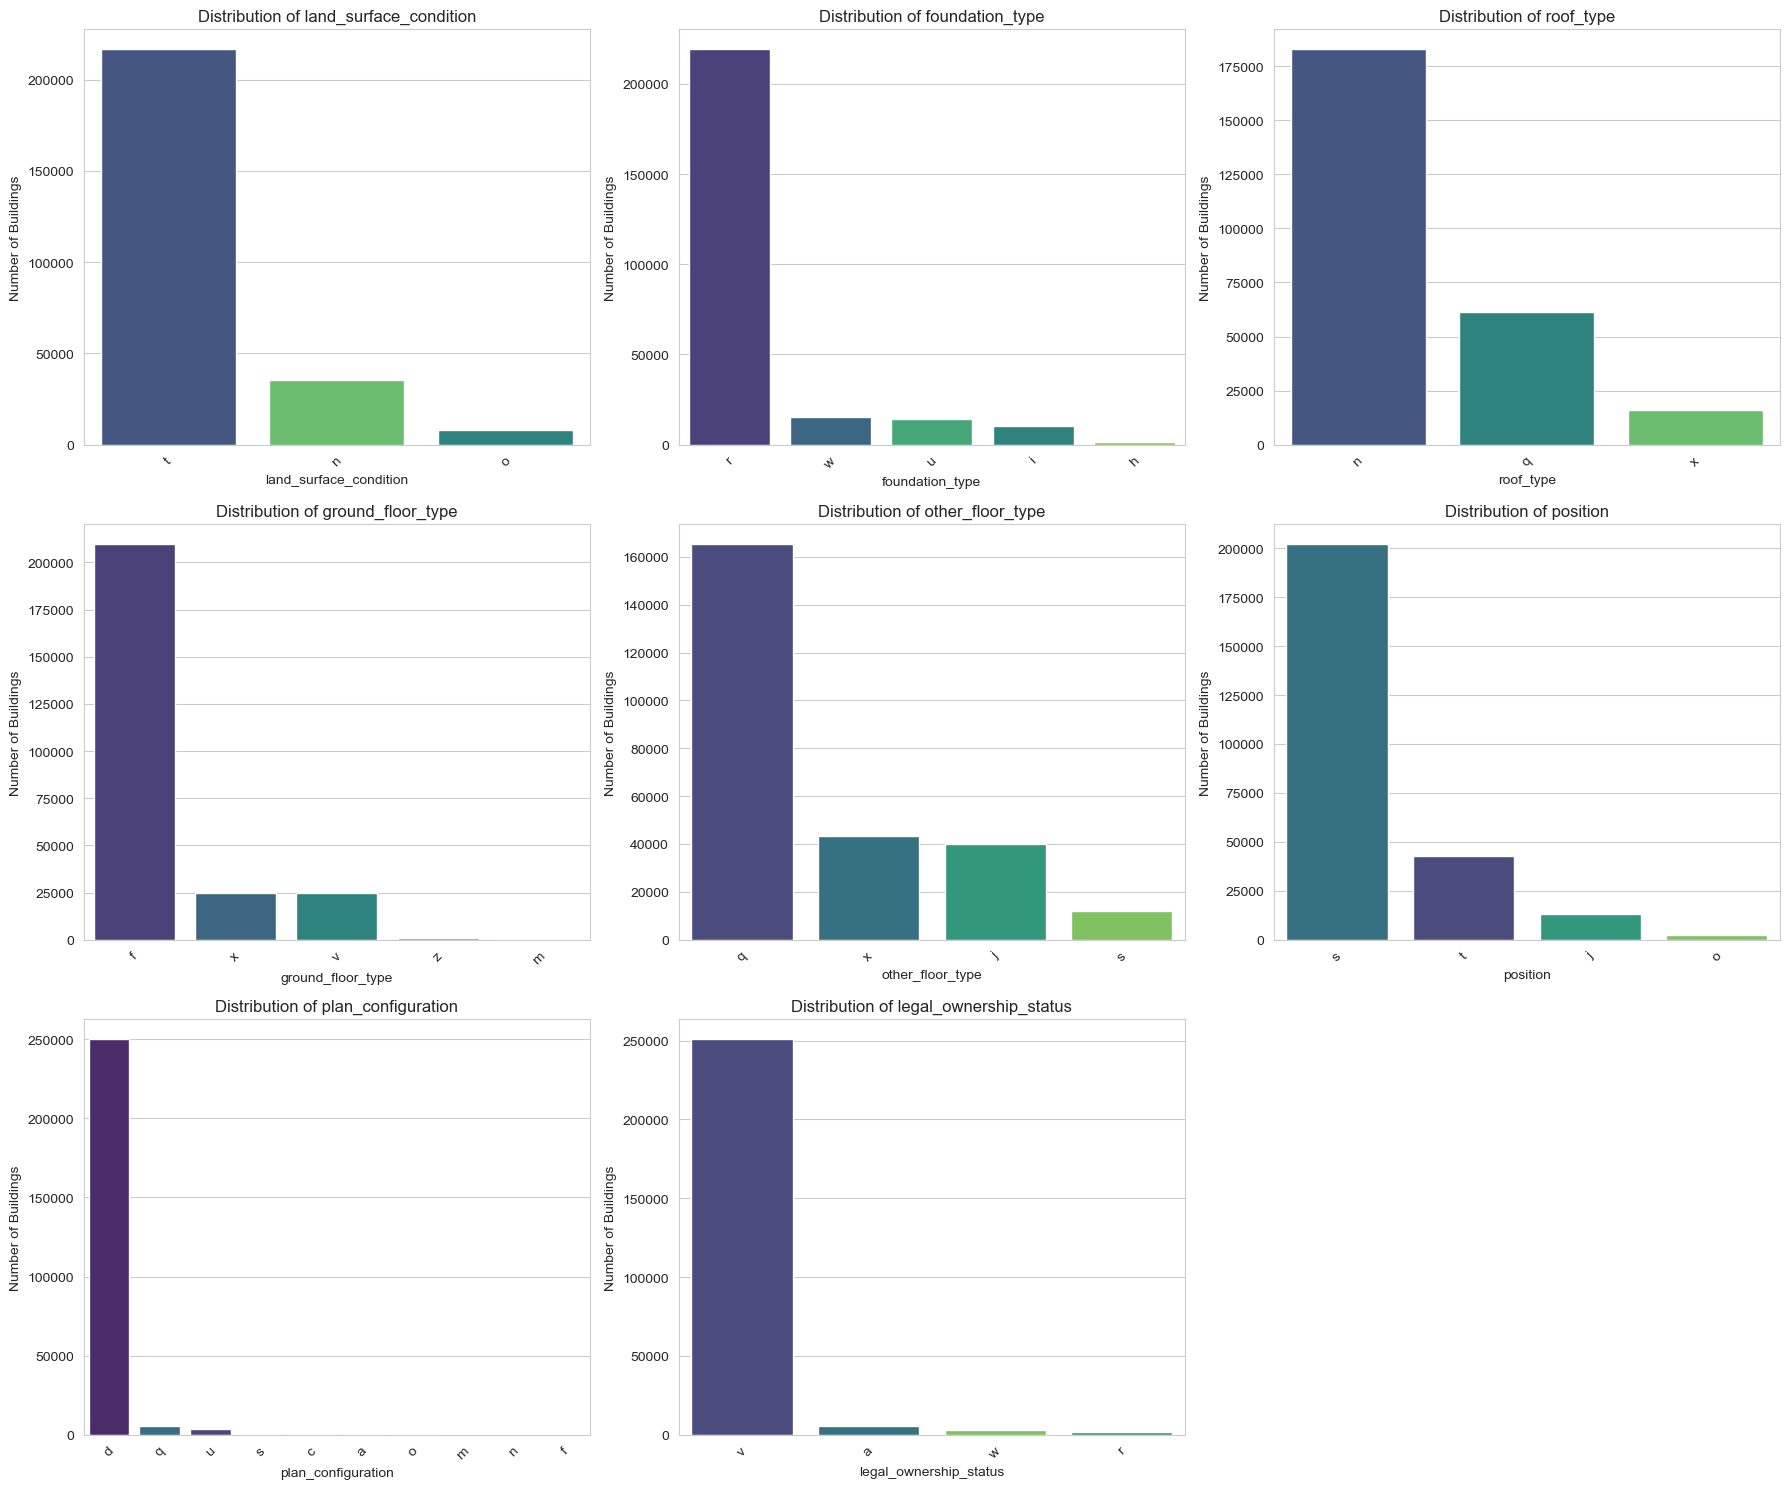

In [23]:
# Visualize categorical feature distributions
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    order = data[feature].value_counts().index

    sns.countplot(
        data=data,
        x=feature,
        order=order,
        hue=feature,
        palette='viridis',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Number of Buildings')
    axes[i].tick_params(axis='x', rotation=45)

# Hide the unused subplot
axes[8].set_visible(False)

plt.tight_layout()
plt.show()

## 4.4 Building Structural Characteristics Analysis

In [24]:
# Identify superstructure and secondary-use features
structural_features = [
    col for col in data.columns
    if col.startswith('has_superstructure_')
]

secondary_use_features = [
    col for col in data.columns
    if col.startswith('has_secondary_use_')
]

print("Superstructure features:", len(structural_features))
print("Secondary-use features:", len(secondary_use_features))

print("\nSuperstructure columns:")
print(structural_features)

print("\nSecondary-use columns:")
print(secondary_use_features)

Superstructure features: 11
Secondary-use features: 10

Superstructure columns:
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other']

Secondary-use columns:
['has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']


In [25]:
# Calculate the number of buildings with each superstructure material
structural_counts = data[structural_features].sum().sort_values(ascending=False)

print("Buildings by Superstructure Material:")
print(structural_counts)

Buildings by Superstructure Material:
has_superstructure_mud_mortar_stone       198561
has_superstructure_timber                  66450
has_superstructure_adobe_mud               23101
has_superstructure_bamboo                  22154
has_superstructure_cement_mortar_brick     19615
has_superstructure_mud_mortar_brick        17761
has_superstructure_rc_non_engineered       11099
has_superstructure_stone_flag               8947
has_superstructure_cement_mortar_stone      4752
has_superstructure_rc_engineered            4133
has_superstructure_other                    3905
dtype: int64


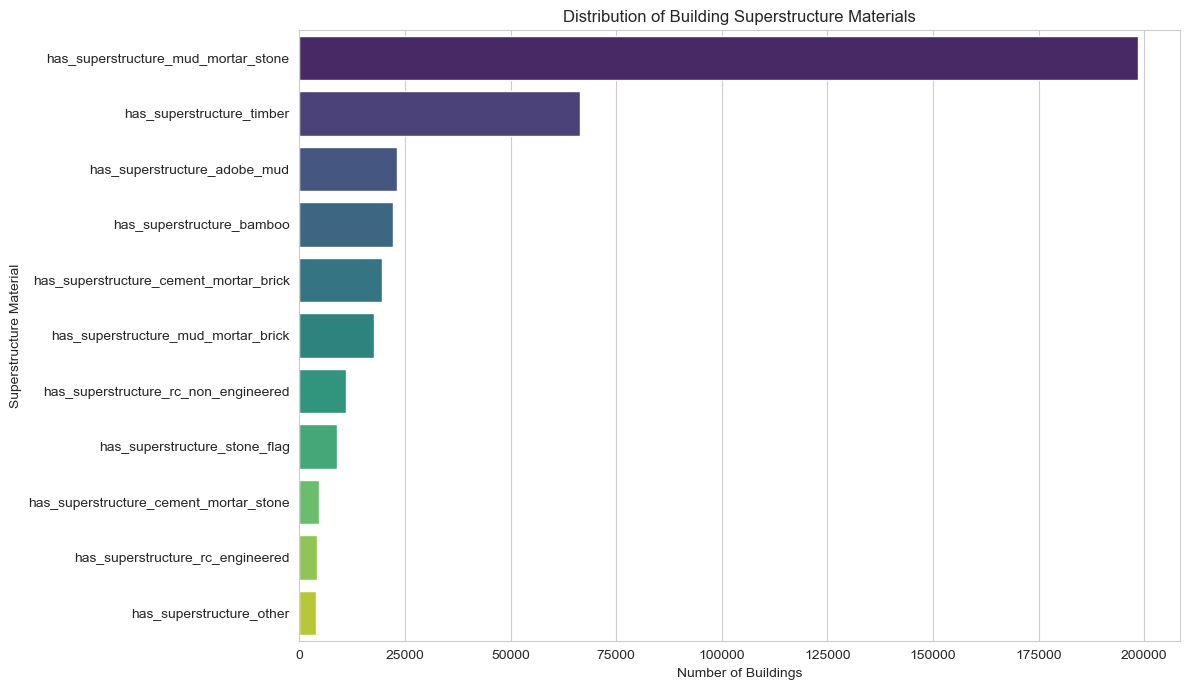

In [26]:
# Visualize superstructure material distribution
plt.figure(figsize=(12, 7))

sns.barplot(
    x=structural_counts.values,
    y=structural_counts.index,
    hue=structural_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Distribution of Building Superstructure Materials')
plt.xlabel('Number of Buildings')
plt.ylabel('Superstructure Material')

plt.tight_layout()
plt.show()

In [27]:
# Calculate the number of buildings with secondary uses
secondary_use_counts = data[secondary_use_features].sum().sort_values(ascending=False)

print("Buildings by Secondary Use:")
print(secondary_use_counts)

Buildings by Secondary Use:
has_secondary_use_agriculture    16777
has_secondary_use_hotel           8763
has_secondary_use_rental          2111
has_secondary_use_other           1334
has_secondary_use_industry         279
has_secondary_use_institution      245
has_secondary_use_school            94
has_secondary_use_health_post       49
has_secondary_use_gov_office        38
has_secondary_use_use_police        23
dtype: int64


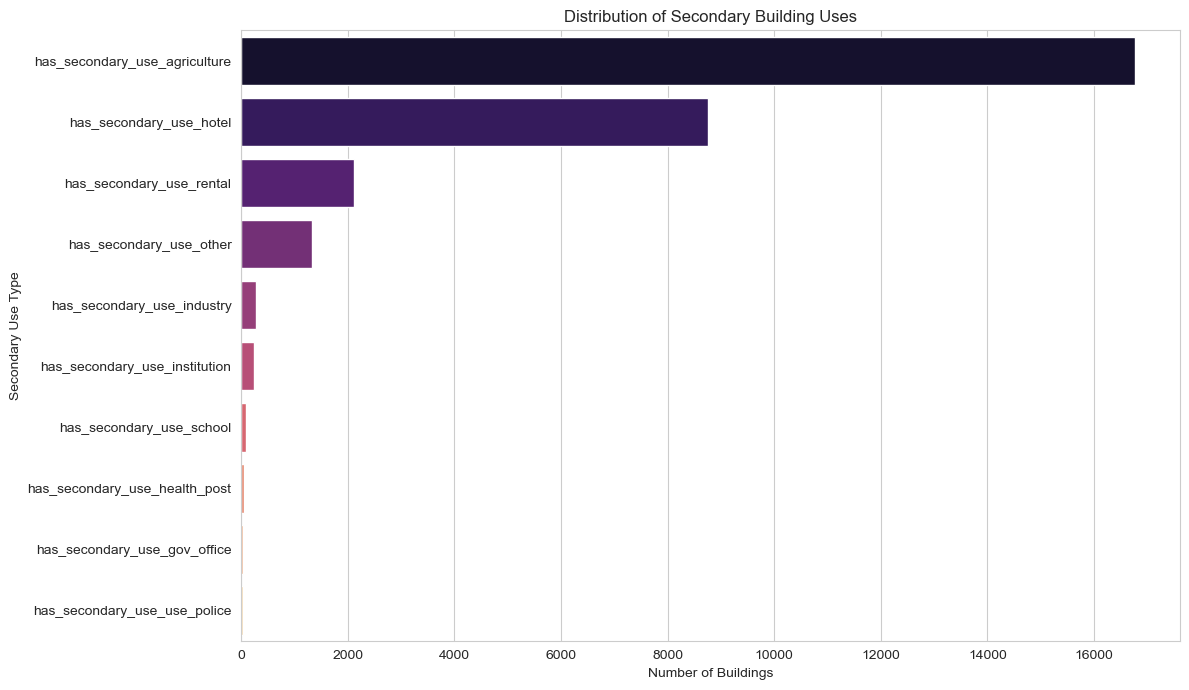

In [28]:
# Visualize secondary-use distribution
plt.figure(figsize=(12, 7))

sns.barplot(
    x=secondary_use_counts.values,
    y=secondary_use_counts.index,
    hue=secondary_use_counts.index,
    palette='magma',
    legend=False
)

plt.title('Distribution of Secondary Building Uses')
plt.xlabel('Number of Buildings')
plt.ylabel('Secondary Use Type')

plt.tight_layout()
plt.show()

## 4.5 Relationship Between Numerical Features and Damage Grade

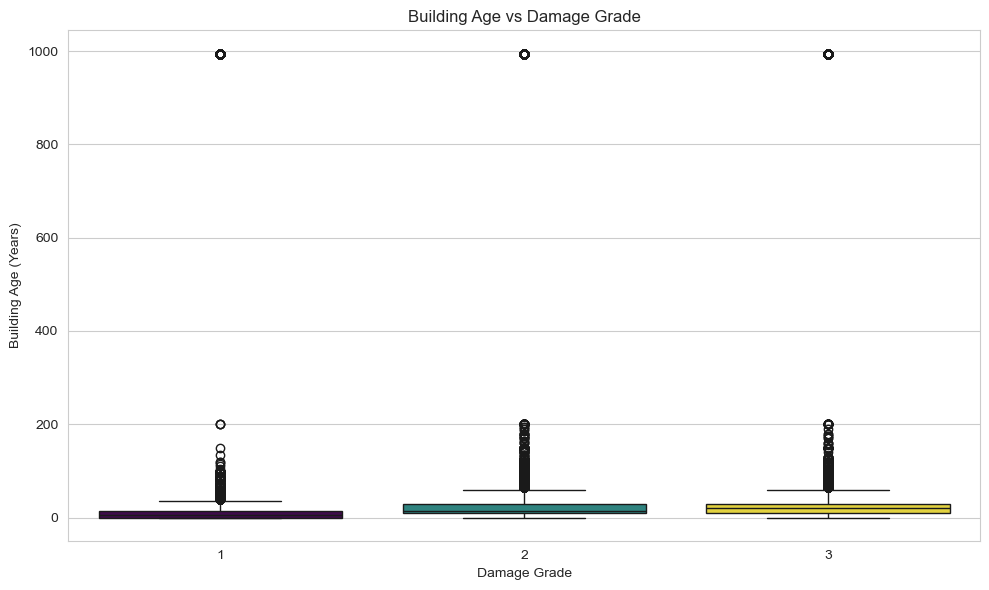

In [29]:
# Analyze building age across damage grades
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='damage_grade',
    y='age',
    hue='damage_grade',
    palette='viridis',
    legend=False
)

plt.title('Building Age vs Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Building Age (Years)')

plt.tight_layout()
plt.show()

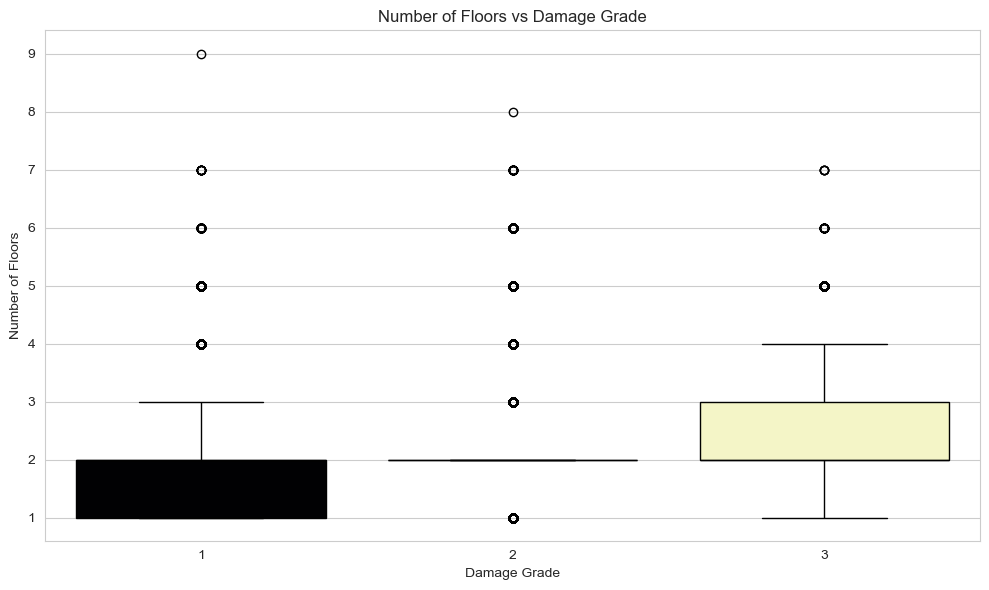

In [30]:
# Analyze number of floors across damage grades
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='damage_grade',
    y='count_floors_pre_eq',
    hue='damage_grade',
    palette='magma',
    legend=False
)

plt.title('Number of Floors vs Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Floors')

plt.tight_layout()
plt.show()

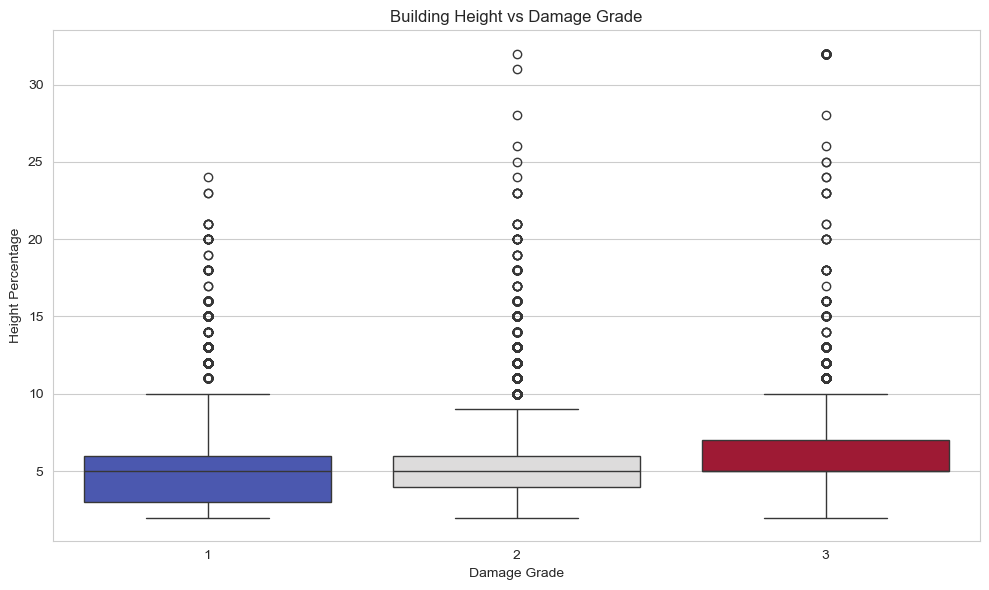

In [31]:
# Analyze building height across damage grades
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='damage_grade',
    y='height_percentage',
    hue='damage_grade',
    palette='coolwarm',
    legend=False
)

plt.title('Building Height vs Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Height Percentage')

plt.tight_layout()
plt.show()

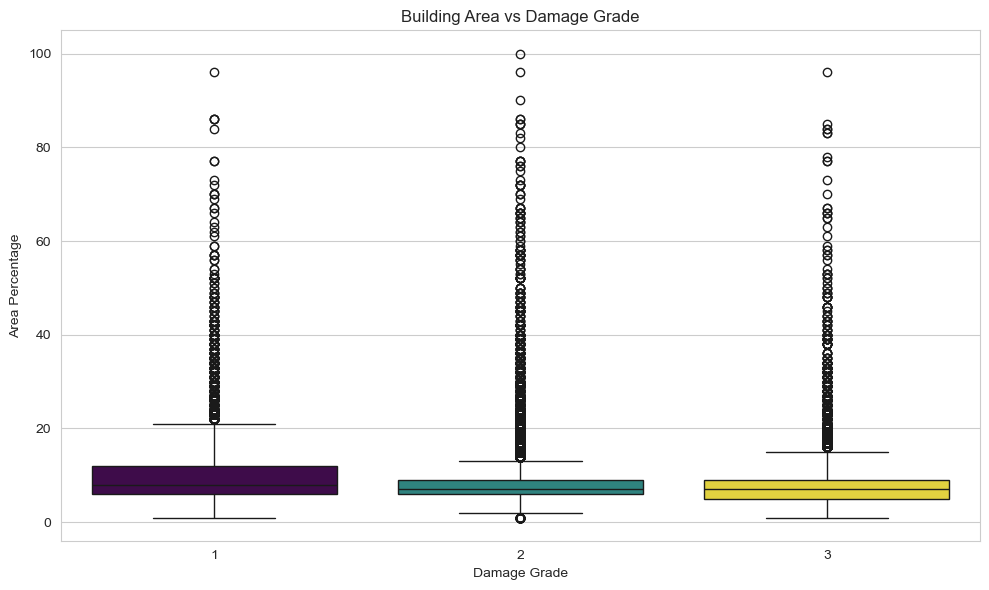

In [32]:
# Analyze building area across damage grades
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='damage_grade',
    y='area_percentage',
    hue='damage_grade',
    palette='viridis',
    legend=False
)

plt.title('Building Area vs Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Area Percentage')

plt.tight_layout()
plt.show()

## 4.6 Relationship Between Structural Characteristics and Damage Grade

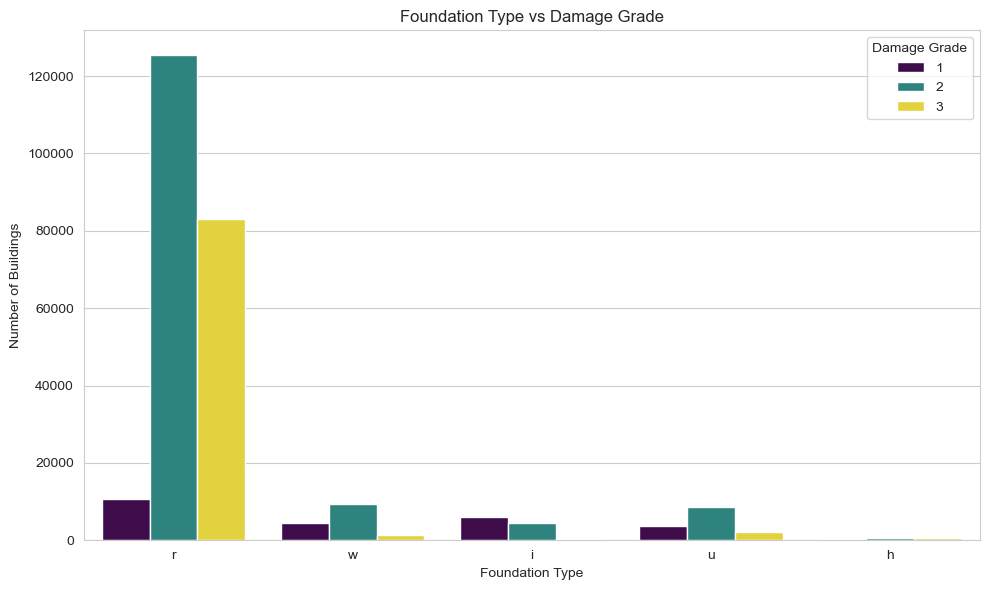

In [33]:
# Foundation type vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='foundation_type',
    hue='damage_grade',
    palette='viridis'
)

plt.title('Foundation Type vs Damage Grade')
plt.xlabel('Foundation Type')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

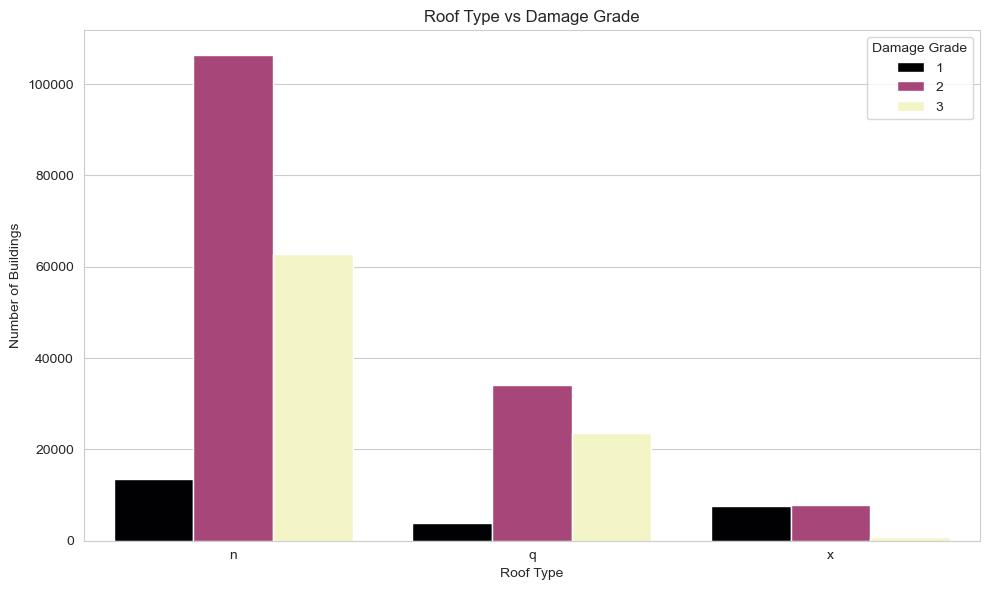

In [34]:
# Roof type vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='roof_type',
    hue='damage_grade',
    palette='magma'
)

plt.title('Roof Type vs Damage Grade')
plt.xlabel('Roof Type')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

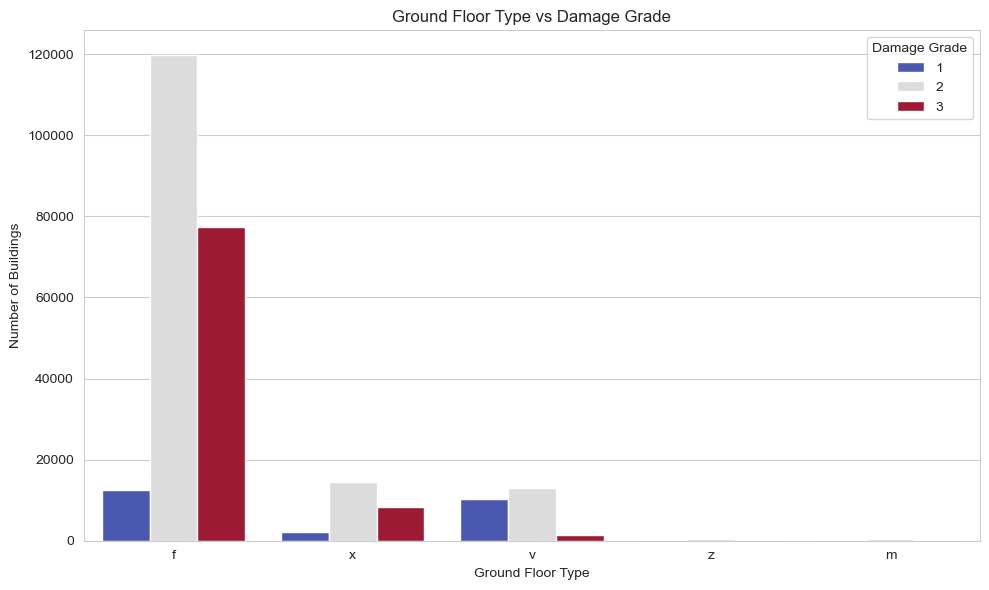

In [35]:
# Ground floor type vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='ground_floor_type',
    hue='damage_grade',
    palette='coolwarm'
)

plt.title('Ground Floor Type vs Damage Grade')
plt.xlabel('Ground Floor Type')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

## 4.7 Additional Categorical Features vs Damage Grade

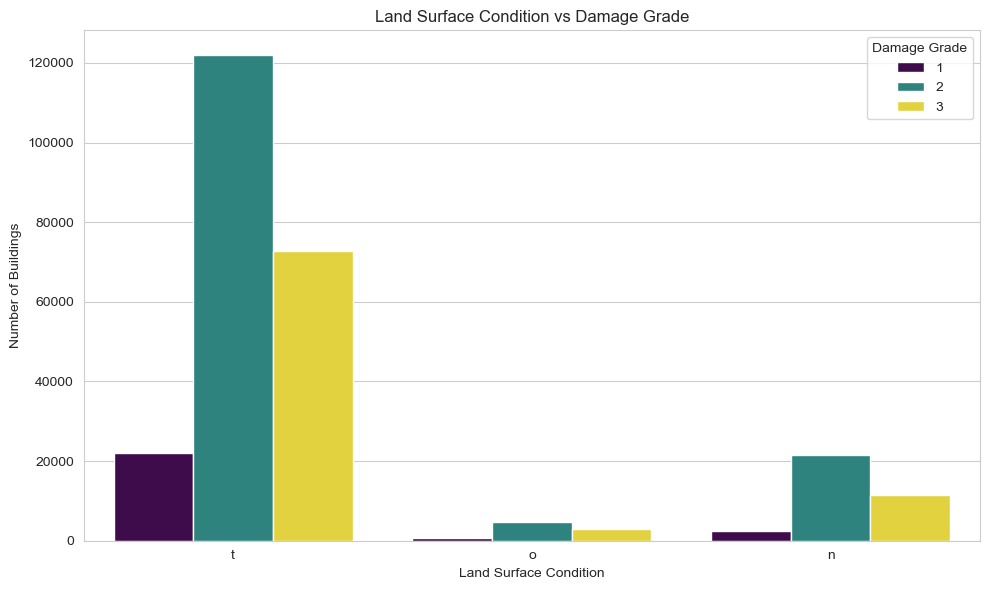

In [36]:
# Land surface condition vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='land_surface_condition',
    hue='damage_grade',
    palette='viridis'
)

plt.title('Land Surface Condition vs Damage Grade')
plt.xlabel('Land Surface Condition')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

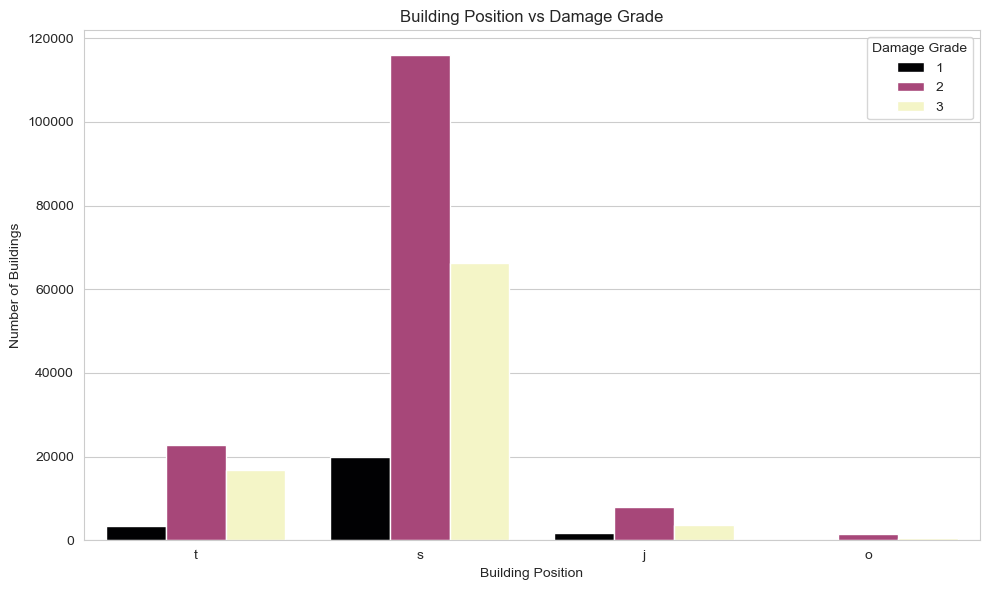

In [37]:
# Building position vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='position',
    hue='damage_grade',
    palette='magma'
)

plt.title('Building Position vs Damage Grade')
plt.xlabel('Building Position')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

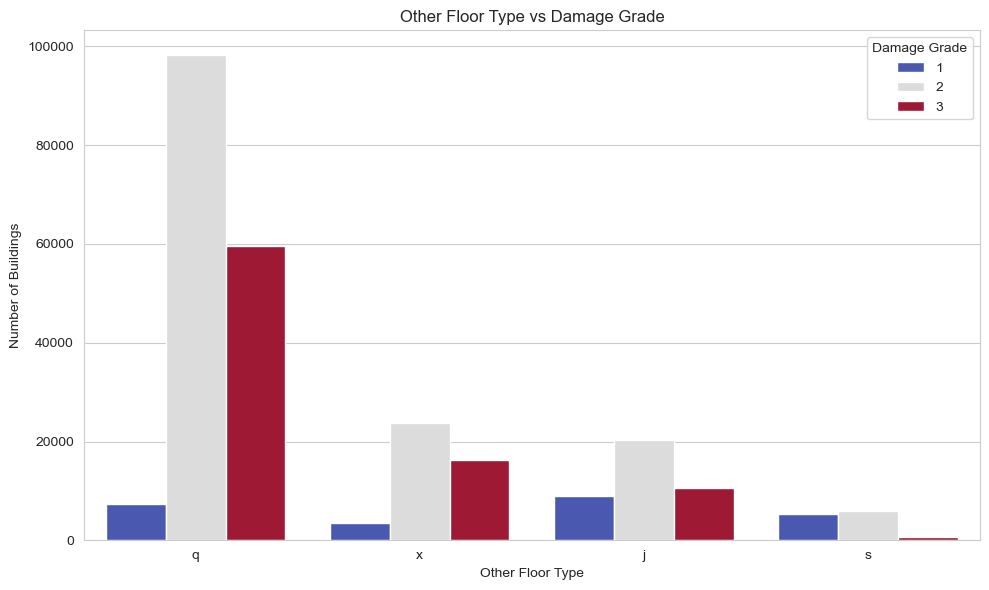

In [38]:
# Other floor type vs damage grade
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x='other_floor_type',
    hue='damage_grade',
    palette='coolwarm'
)

plt.title('Other Floor Type vs Damage Grade')
plt.xlabel('Other Floor Type')
plt.ylabel('Number of Buildings')
plt.legend(title='Damage Grade')

plt.tight_layout()
plt.show()

## 4.8 Geographical Distribution of Earthquake Damage

In [39]:
# Damage distribution across Geo Level 1
geo1_damage = pd.crosstab(
    data['geo_level_1_id'],
    data['damage_grade']
)

print("Damage distribution across Geo Level 1:")
geo1_damage.head(10)

Damage distribution across Geo Level 1:


damage_grade,1,2,3
geo_level_1_id,,,
0,337,3075,599
1,411,1985,305
2,85,610,236
3,245,4550,2745
4,521,11164,2883
5,446,2014,230
6,2108,16222,6051
7,1033,11273,6688
8,654,8513,9913


In [40]:
# Top 10 Geo Level 1 regions by building count
geo1_counts = data['geo_level_1_id'].value_counts().head(10)

print("Top 10 Geo Level 1 regions by building count:")
print(geo1_counts)

Top 10 Geo Level 1 regions by building count:
geo_level_1_id
6     24381
26    22615
10    22079
17    21813
8     19080
7     18994
20    17216
21    14889
4     14568
27    12532
Name: count, dtype: int64


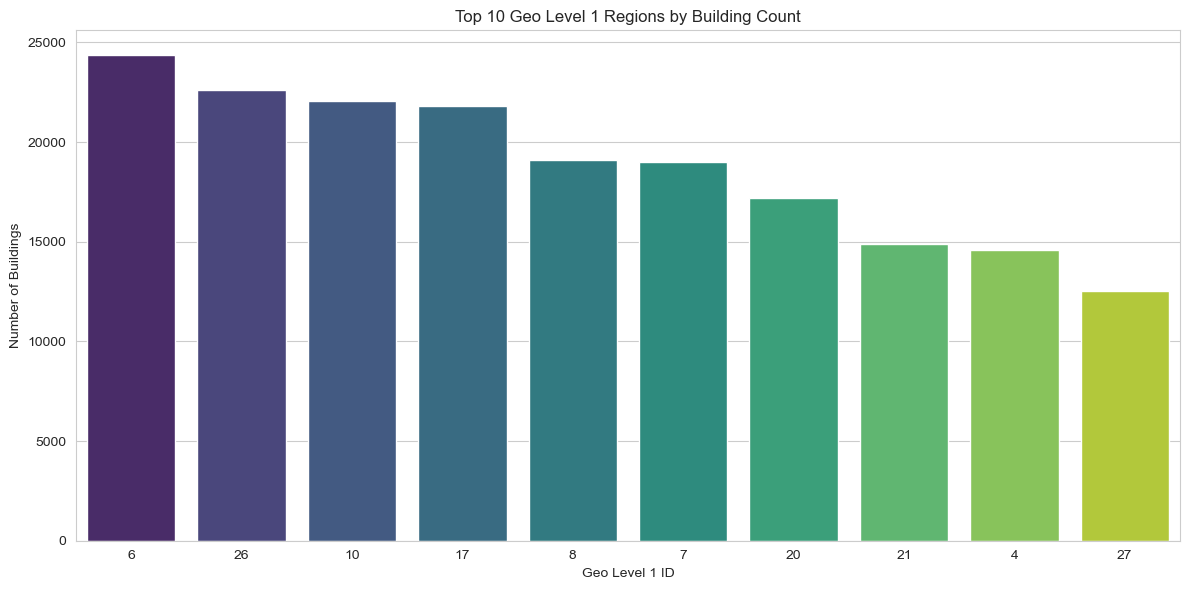

In [41]:
# Visualize building counts across top Geo Level 1 regions
plt.figure(figsize=(12, 6))

sns.barplot(
    x=geo1_counts.index.astype(str),
    y=geo1_counts.values,
    hue=geo1_counts.index.astype(str),
    palette='viridis',
    legend=False
)

plt.title('Top 10 Geo Level 1 Regions by Building Count')
plt.xlabel('Geo Level 1 ID')
plt.ylabel('Number of Buildings')

plt.tight_layout()
plt.show()

In [42]:
# Calculate percentage of damage grades within each Geo Level 1 region
geo1_damage_percentage = pd.crosstab(
    data['geo_level_1_id'],
    data['damage_grade'],
    normalize='index'
) * 100

# Select top 10 regions by building count
top_geo1 = geo1_counts.index

geo1_damage_percentage_top10 = geo1_damage_percentage.loc[top_geo1]

print("Damage grade percentage distribution in top 10 Geo Level 1 regions:")
geo1_damage_percentage_top10.round(2)

Damage grade percentage distribution in top 10 Geo Level 1 regions:


damage_grade,1,2,3
geo_level_1_id,,,
6,8.65,66.54,24.82
26,35.50,55.91,8.59
10,5.48,54.83,39.68
17,1.31,17.94,80.75
8,3.43,44.62,51.95
7,5.44,59.35,35.21
20,19.23,68.89,11.88
21,2.16,39.34,58.50
4,3.58,76.63,19.79


## 4.9 Damage Distribution Across Superstructure Materials

In [43]:
# Calculate damage grade distribution for each superstructure material
superstructure_damage = {}

for feature in structural_features:
    buildings_with_material = data[data[feature] == 1]

    damage_distribution = (
        buildings_with_material['damage_grade']
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    superstructure_damage[feature] = damage_distribution

superstructure_damage_df = pd.DataFrame(superstructure_damage).T

superstructure_damage_df.columns = [
    f'Damage Grade {grade}' for grade in superstructure_damage_df.columns
]

superstructure_damage_df.round(2)

,Damage Grade 1,Damage Grade 2,Damage Grade 3
has_superstructure_adobe_mud,2.57,60.18,37.25
has_superstructure_mud_mortar_stone,4.41,57.39,38.20
has_superstructure_stone_flag,2.03,50.68,47.29
has_superstructure_cement_mortar_stone,17.45,68.35,14.20
has_superstructure_mud_mortar_brick,3.51,65.86,30.63
has_superstructure_cement_mortar_brick,36.22,58.23,5.55
has_superstructure_timber,11.50,60.48,28.02
has_superstructure_bamboo,12.81,63.20,23.99
has_superstructure_rc_non_engineered,34.75,52.55,12.70
has_superstructure_rc_engineered,64.26,33.92,1.81


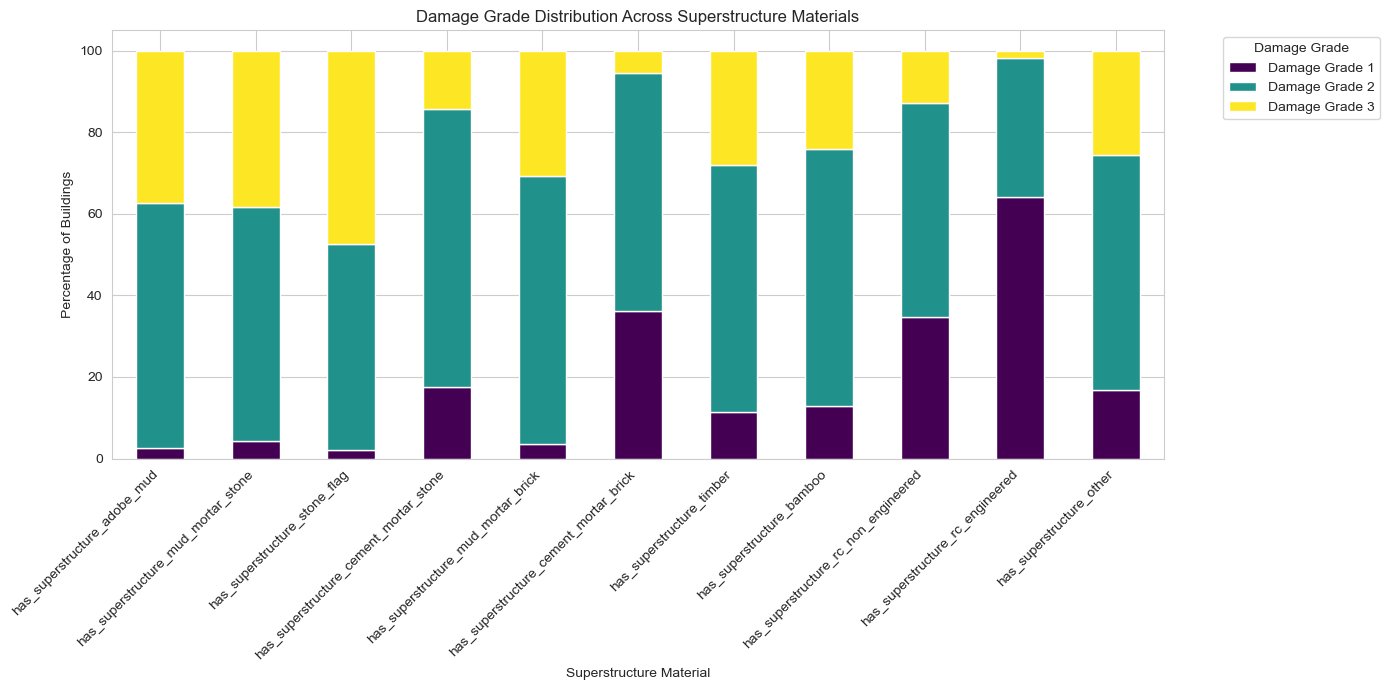

In [44]:
# Visualize damage grade percentages by superstructure material
superstructure_damage_df.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='viridis'
)

plt.title('Damage Grade Distribution Across Superstructure Materials')
plt.xlabel('Superstructure Material')
plt.ylabel('Percentage of Buildings')
plt.legend(title='Damage Grade', bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 4.10 Comparative Geographical Damage Analysis

In [45]:
# Calculate damage grade percentages for Geo Level 1
geo1_damage_percentage = pd.crosstab(
    data['geo_level_1_id'],
    data['damage_grade'],
    normalize='index'
) * 100

# Rename columns
geo1_damage_percentage.columns = [
    f'Damage Grade {grade}' for grade in geo1_damage_percentage.columns
]

# Identify top 10 regions by number of buildings
top_10_geo1 = data['geo_level_1_id'].value_counts().head(10).index

# Display percentage distribution
geo1_damage_percentage.loc[top_10_geo1].round(2)

,Damage Grade 1,Damage Grade 2,Damage Grade 3
geo_level_1_id,,,
6,8.65,66.54,24.82
26,35.50,55.91,8.59
10,5.48,54.83,39.68
17,1.31,17.94,80.75
8,3.43,44.62,51.95
7,5.44,59.35,35.21
20,19.23,68.89,11.88
21,2.16,39.34,58.50
4,3.58,76.63,19.79


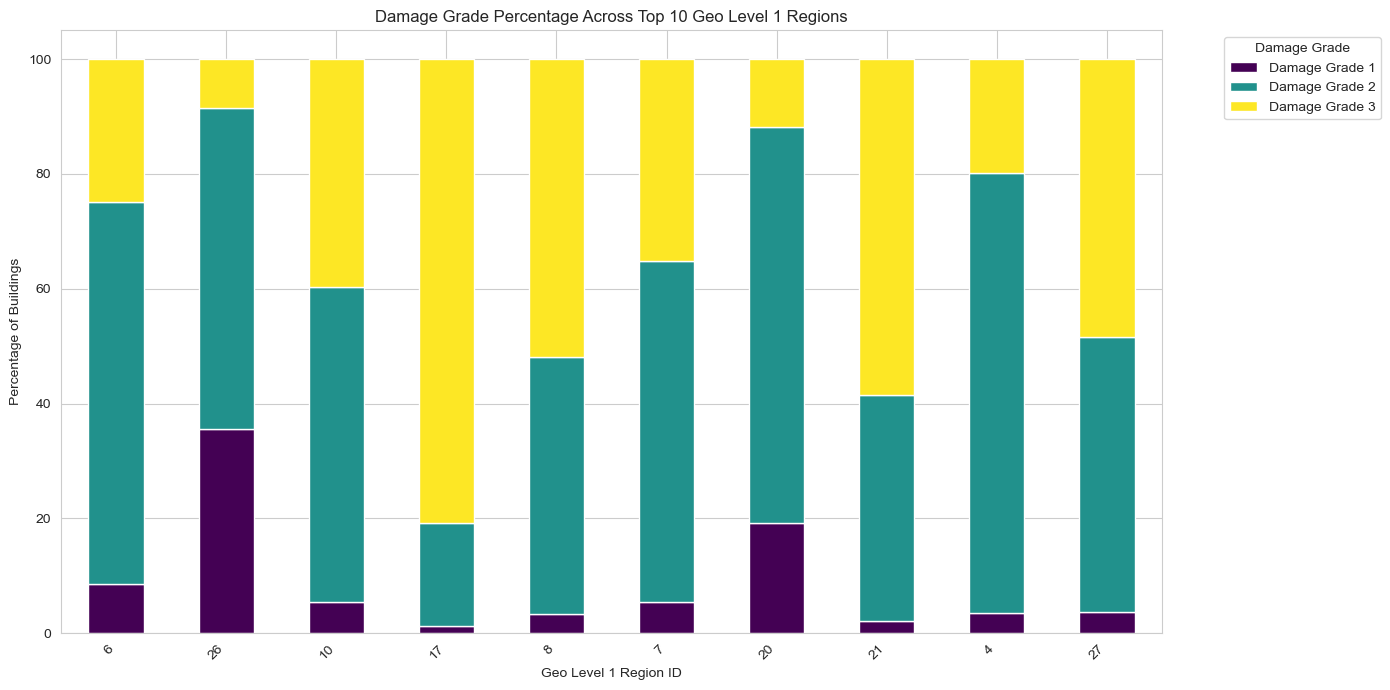

In [46]:
# Visualize damage grade percentages across top 10 Geo Level 1 regions
geo1_damage_percentage.loc[top_10_geo1].plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='viridis'
)

plt.title('Damage Grade Percentage Across Top 10 Geo Level 1 Regions')
plt.xlabel('Geo Level 1 Region ID')
plt.ylabel('Percentage of Buildings')
plt.legend(title='Damage Grade', bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 4.11 Building Age Group Analysis

In [47]:
# Create age categories
data['age_group'] = pd.cut(
    data['age'],
    bins=[-1, 10, 20, 30, 50, 100, float('inf')],
    labels=['0-10', '11-20', '21-30', '31-50', '51-100', '100+']
)

print("Building age groups created successfully!")

data['age_group'].value_counts().sort_index()

Building age groups created successfully!


age_group
0-10      98634
11-20     68192
21-30     42394
31-50     33237
51-100    16020
100+       2124
Name: count, dtype: int64

In [48]:
# Calculate damage distribution by age group
age_damage_percentage = pd.crosstab(
    data['age_group'],
    data['damage_grade'],
    normalize='index'
) * 100

# Rename columns
age_damage_percentage.columns = [
    f'Damage Grade {grade}' for grade in age_damage_percentage.columns
]

age_damage_percentage.round(2)

,Damage Grade 1,Damage Grade 2,Damage Grade 3
age_group,,,
0-10,17.40,54.87,27.73
11-20,7.09,57.73,35.18
21-30,4.18,57.83,37.99
31-50,2.78,58.04,39.17
51-100,1.52,60.44,38.04
100+,8.90,60.12,30.98


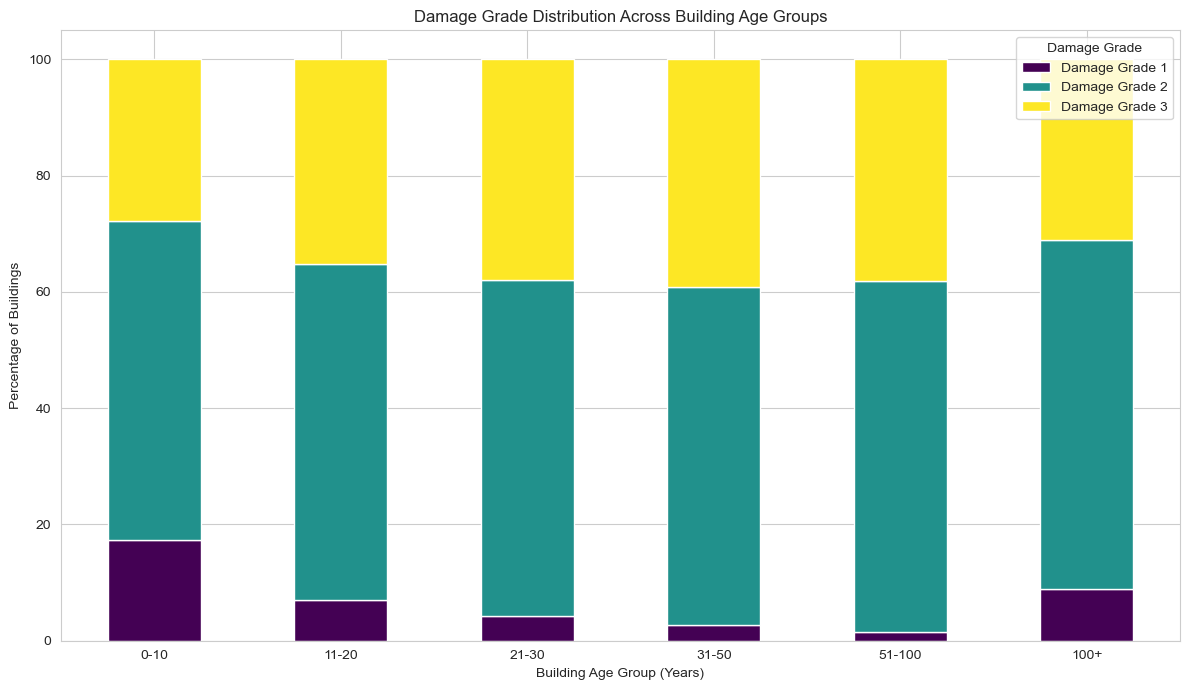

In [49]:
# Plot damage grade distribution across building age groups
age_damage_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7),
    colormap='viridis'
)

plt.title('Damage Grade Distribution Across Building Age Groups')
plt.xlabel('Building Age Group (Years)')
plt.ylabel('Percentage of Buildings')
plt.legend(title='Damage Grade')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 4.12 Building Height and Floor Analysis

In [50]:
# Create building floor categories

data['floor_group'] = pd.cut(
    data['count_floors_pre_eq'],
    bins=[0, 1, 2, 3, 5, 10, float('inf')],
    labels=['1 Floor', '2 Floors', '3 Floors', '4-5 Floors', '6-10 Floors', '11+ Floors'],
    include_lowest=True
)

print("Floor categories created successfully!")

data['floor_group'].value_counts().sort_index()

Floor categories created successfully!


floor_group
1 Floor         40441
2 Floors       156623
3 Floors        55617
4-5 Floors       7670
6-10 Floors       250
11+ Floors          0
Name: count, dtype: int64

In [51]:
# Calculate damage distribution across floor categories
floor_damage_percentage = pd.crosstab(
    data['floor_group'],
    data['damage_grade'],
    normalize='index'
) * 100

# Rename columns
floor_damage_percentage.columns = [
    f'Damage Grade {grade}' for grade in floor_damage_percentage.columns
]

floor_damage_percentage.round(2)

,Damage Grade 1,Damage Grade 2,Damage Grade 3
floor_group,,,
1 Floor,22.18,51.43,26.39
2 Floors,8.04,60.00,31.96
3 Floors,4.56,51.21,44.23
4-5 Floors,12.53,63.30,24.17
6-10 Floors,25.60,63.60,10.80


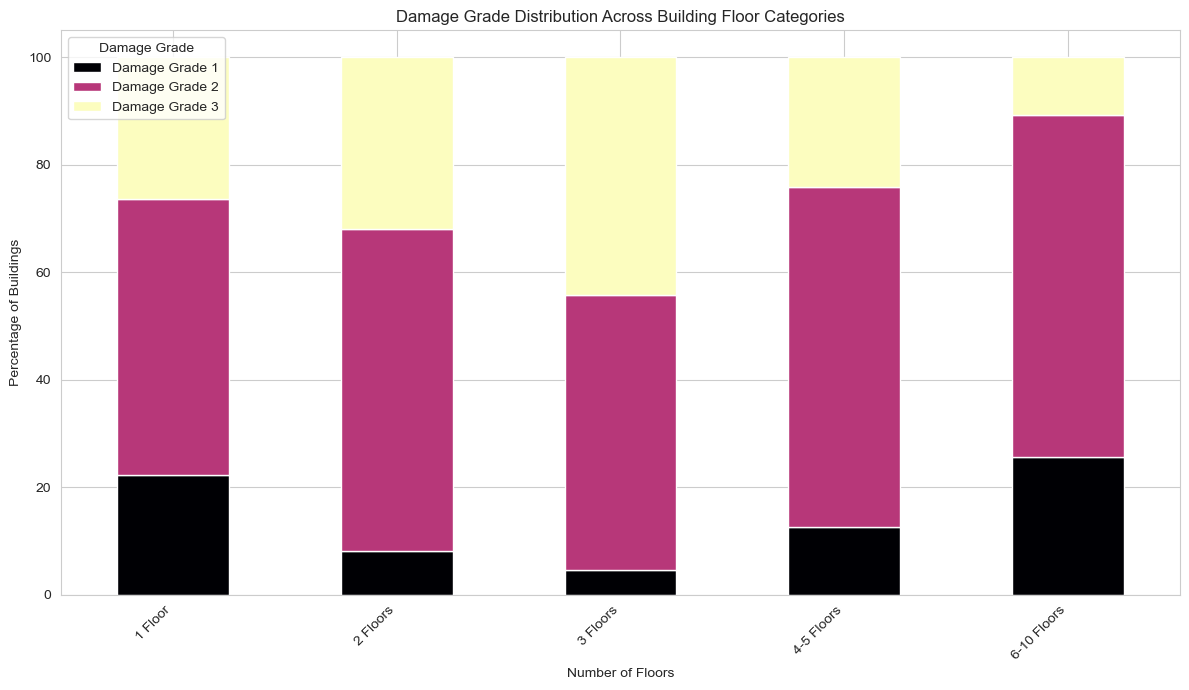

In [52]:
# Plot damage grade distribution by floor category
floor_damage_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7),
    colormap='magma'
)

plt.title('Damage Grade Distribution Across Building Floor Categories')
plt.xlabel('Number of Floors')
plt.ylabel('Percentage of Buildings')
plt.legend(title='Damage Grade')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [53]:
# Compare building height percentage across damage grades
height_damage = data.groupby('damage_grade')['height_percentage'].agg(
    ['mean', 'median', 'std']
)

print("Building Height Statistics by Damage Grade:")
height_damage.round(2)

Building Height Statistics by Damage Grade:


,mean,median,std
damage_grade,,,
1,5.15,5.00,2.51
2,5.43,5.00,1.83
3,5.52,5.00,1.87


## 4.13 Building Occupancy and Damage Analysis

In [54]:
# Analyze number of families across damage grades
families_damage = data.groupby('damage_grade')['count_families'].agg(
    ['mean', 'median', 'std']
)

print("Number of Families Statistics by Damage Grade:")
families_damage.round(2)

Number of Families Statistics by Damage Grade:


,mean,median,std
damage_grade,,,
1,0.92,1.00,0.50
2,0.98,1.00,0.40
3,1.01,1.00,0.42


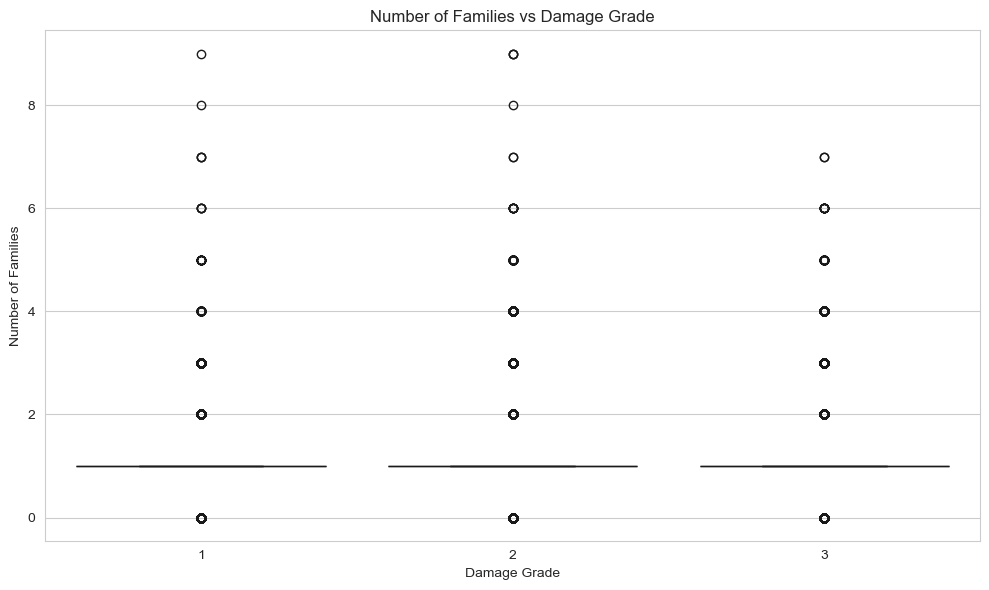

In [55]:
# Visualize family count across damage grades
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='damage_grade',
    y='count_families',
    hue='damage_grade',
    palette='viridis',
    legend=False
)

plt.title('Number of Families vs Damage Grade')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Families')

plt.tight_layout()
plt.show()

In [56]:
# Calculate damage grade distribution for buildings with secondary use
secondary_use_damage = {}

for feature in secondary_use_features:
    buildings_with_use = data[data[feature] == 1]

    damage_distribution = (
        buildings_with_use['damage_grade']
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    secondary_use_damage[feature] = damage_distribution

secondary_use_damage_df = pd.DataFrame(secondary_use_damage).T

secondary_use_damage_df.columns = [
    f'Damage Grade {grade}' for grade in secondary_use_damage_df.columns
]

secondary_use_damage_df.round(2)

,Damage Grade 1,Damage Grade 2,Damage Grade 3
has_secondary_use_agriculture,4.94,63.65,31.41
has_secondary_use_hotel,25.29,57.72,16.99
has_secondary_use_rental,41.54,49.79,8.67
has_secondary_use_institution,40.41,52.65,6.94
has_secondary_use_school,31.91,50.00,18.09
has_secondary_use_industry,21.15,54.48,24.37
has_secondary_use_health_post,24.49,65.31,10.20
has_secondary_use_gov_office,34.21,55.26,10.53
has_secondary_use_use_police,17.39,52.17,30.43
has_secondary_use_other,13.12,63.87,23.01


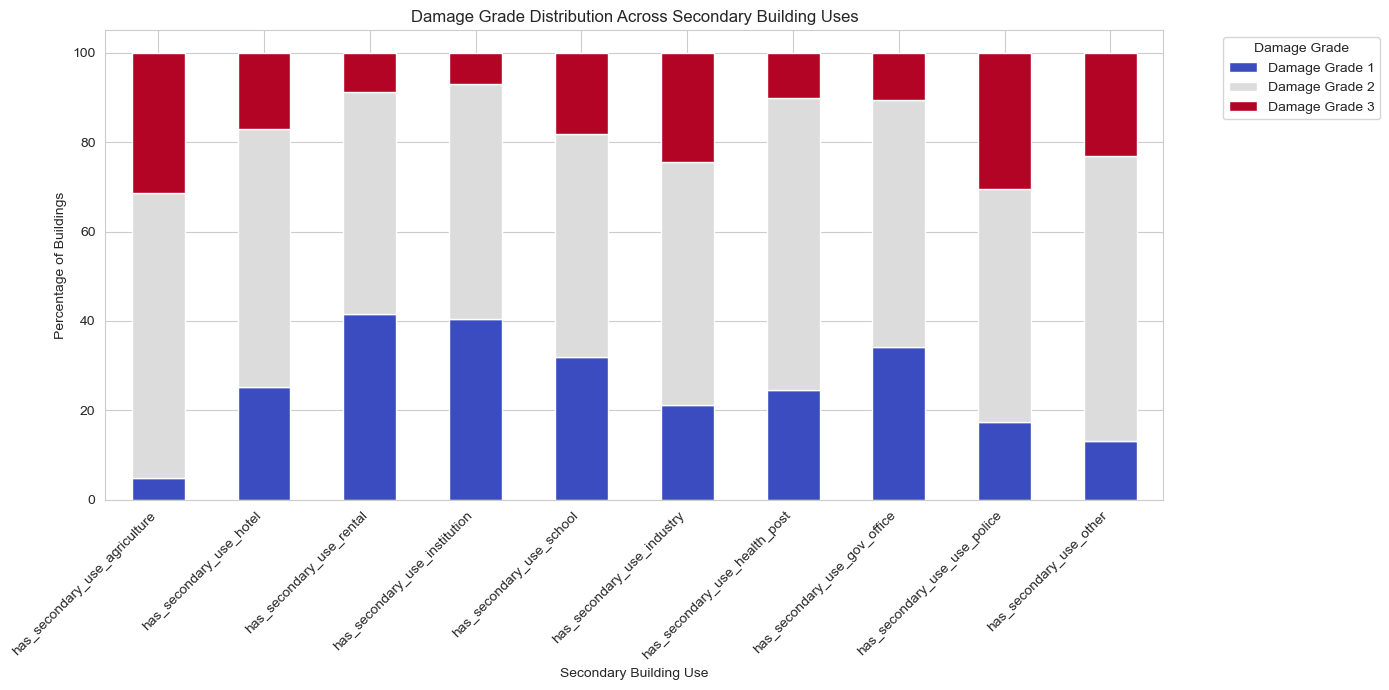

In [57]:
# Visualize damage percentages across secondary building uses
secondary_use_damage_df.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='coolwarm'
)

plt.title('Damage Grade Distribution Across Secondary Building Uses')
plt.xlabel('Secondary Building Use')
plt.ylabel('Percentage of Buildings')
plt.legend(title='Damage Grade', bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 4.14 Correlation Analysis

In [58]:
# Correlation Analysis

# Select numerical building characteristics and target variable
correlation_features = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families',
    'damage_grade'
]

# Create correlation dataset
correlation_data = data[correlation_features]

# Calculate Pearson correlation matrix
correlation_matrix = correlation_data.corr()

# Display correlation matrix
correlation_matrix.round(2)

,count_floors_pre_eq,age,area_percentage,height_percentage,count_families,damage_grade
count_floors_pre_eq,1.00,0.09,0.10,0.77,0.09,0.12
age,0.09,1.00,-0.00,0.06,0.01,0.03
area_percentage,0.10,-0.00,1.00,0.20,0.09,-0.13
height_percentage,0.77,0.06,0.20,1.00,0.06,0.05
count_families,0.09,0.01,0.09,0.06,1.00,0.06
damage_grade,0.12,0.03,-0.13,0.05,0.06,1.00


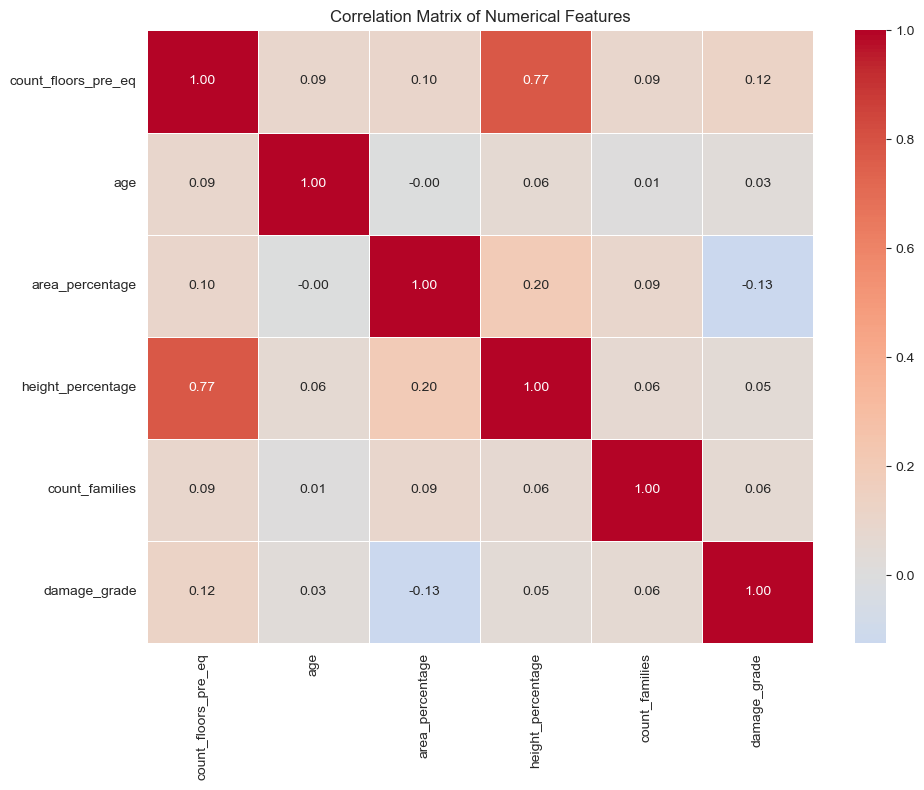

In [59]:
# Visualize correlation matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Features')

plt.tight_layout()
plt.show()

## 4.15 Key Damage Pattern Analysis

In [60]:
# Filter buildings with severe damage
severe_damage = data[data['damage_grade'] == 3]

print("Total buildings with Damage Grade 3:", len(severe_damage))

print("\nPercentage of buildings with severe damage:",
      round((len(severe_damage) / len(data)) * 100, 2), "%")

Total buildings with Damage Grade 3: 87218

Percentage of buildings with severe damage: 33.47 %


In [61]:
# Severe damage percentage by foundation type
foundation_severe = pd.crosstab(
    data['foundation_type'],
    data['damage_grade'] == 3,
    normalize='index'
) * 100

foundation_severe = foundation_severe.rename(
    columns={False: 'Non-Severe Damage (%)', True: 'Severe Damage (%)'}
)

foundation_severe.round(2)

damage_grade,Non-Severe Damage (%),Severe Damage (%)
foundation_type,,
h,64.71,35.29
i,97.91,2.09
r,62.15,37.85
u,85.76,14.24
w,90.11,9.89


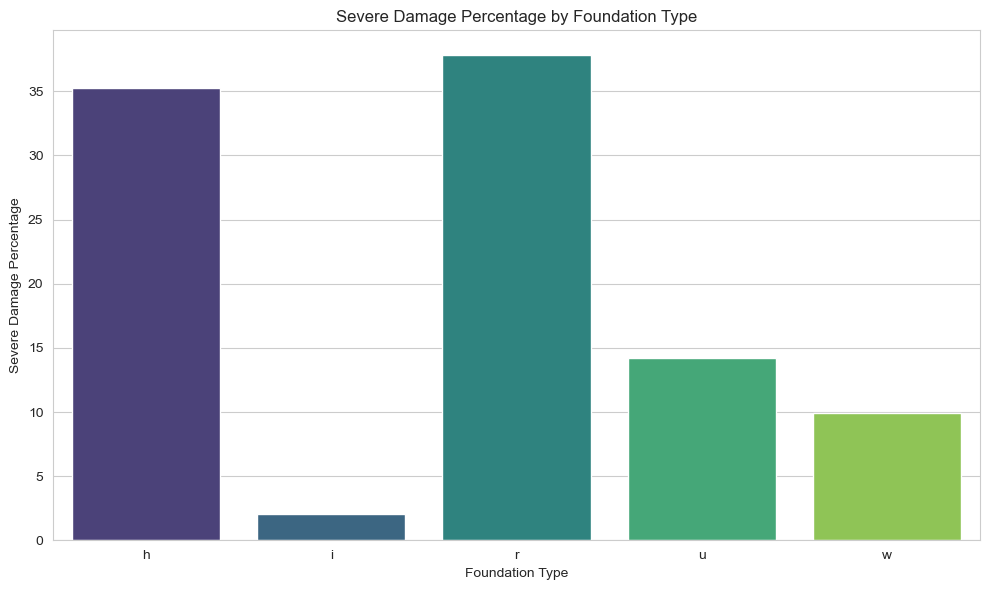

In [62]:
# Plot severe damage percentage by foundation type
plt.figure(figsize=(10, 6))

sns.barplot(
    data=foundation_severe.reset_index(),
    x='foundation_type',
    y='Severe Damage (%)',
    hue='foundation_type',
    palette='viridis',
    legend=False
)

plt.title('Severe Damage Percentage by Foundation Type')
plt.xlabel('Foundation Type')
plt.ylabel('Severe Damage Percentage')

plt.tight_layout()
plt.show()

In [63]:
# Severe damage percentage by roof type
roof_severe = pd.crosstab(
    data['roof_type'],
    data['damage_grade'] == 3,
    normalize='index'
) * 100

roof_severe = roof_severe.rename(
    columns={False: 'Non-Severe Damage (%)', True: 'Severe Damage (%)'}
)

roof_severe.round(2)

damage_grade,Non-Severe Damage (%),Severe Damage (%)
roof_type,,
n,65.63,34.37
q,61.61,38.39
x,95.50,4.50


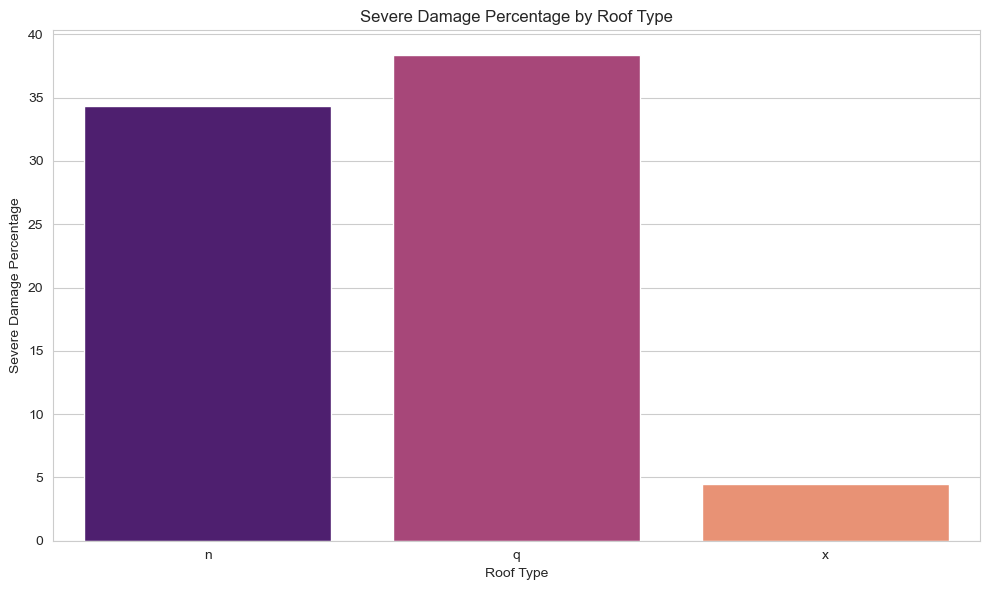

In [64]:
# Plot severe damage percentage by roof type
plt.figure(figsize=(10, 6))

sns.barplot(
    data=roof_severe.reset_index(),
    x='roof_type',
    y='Severe Damage (%)',
    hue='roof_type',
    palette='magma',
    legend=False
)

plt.title('Severe Damage Percentage by Roof Type')
plt.xlabel('Roof Type')
plt.ylabel('Severe Damage Percentage')

plt.tight_layout()
plt.show()

## 4.16 Exploratory Data Analysis – Key Findings

### 1. Target Variable Distribution
The target variable `damage_grade` showed an imbalanced distribution. Damage Grade 2 represented the majority of buildings (56.89%), followed by Damage Grade 3 (33.47%) and Damage Grade 1 (9.64%). This imbalance was considered during model training and evaluation.

### 2. Numerical Features
Numerical features such as building age, number of floors, building area, height percentage, and family count were analyzed using histograms and boxplots. These visualizations helped identify distributions, variability, and potential outliers in building characteristics.

### 3. Categorical Features
Categorical features, including foundation type, roof type, ground floor type, land surface condition, building position, and other floor types, showed variations in their distributions. These characteristics were further investigated in relation to earthquake damage grades.

### 4. Structural Characteristics
Building construction materials and superstructure indicators were analyzed to understand the structural characteristics of the buildings. The analysis highlighted the importance of examining construction-related features when assessing earthquake damage.

### 5. Geographical Patterns
Damage distributions varied across geographical regions. Analysis of Geo Level 1 identifiers showed differences in the percentage of buildings classified under each damage grade, indicating regional variation in observed earthquake damage.

### 6. Feature Relationships with Damage Grade
Numerical and categorical features were compared against damage grades using boxplots, count plots, and percentage-based visualizations. These analyses helped identify patterns between building characteristics and damage severity.

### 7. Building Age and Height
Damage distributions varied across building age groups. Buildings in the 31–50 year age group had the highest observed proportion of Grade 3 damage (39.17%) among the analyzed age groups. Mean building height percentage also increased slightly across damage grades, from 5.15 for Grade 1 to 5.52 for Grade 3.

### 8. Correlation Analysis
Correlation analysis was performed using numerical building characteristics and the target variable. The number of floors and height percentage showed a positive correlation of approximately 0.77. Geographical identifiers were excluded from the correlation analysis because they represent categorical locations rather than continuous numerical measurements.

### 9. Severe Damage Analysis
Approximately 33.47% of buildings were classified as Damage Grade 3. Severe damage percentages varied across foundation and roof categories. These variations highlighted the importance of investigating construction characteristics when assessing building vulnerability.

### EDA Conclusion
Exploratory Data Analysis identified class imbalance, variations in structural characteristics, geographical differences, and relationships between building features and damage severity. These findings provided the foundation for data preprocessing, feature selection, model development, and evaluation.


# 5. Data Preprocessing

In [65]:
# Check dataset dimensions before preprocessing
print("Dataset Shape:", data.shape)
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])

Dataset Shape: (260601, 42)
Number of Rows: 260601
Number of Columns: 42


In [66]:
# Check missing values
missing_values = data.isnull().sum()

print("Total Missing Values:", missing_values.sum())

missing_values[missing_values > 0]

Total Missing Values: 0


Series([], dtype: int64)

In [67]:
# Check duplicate records
duplicate_rows = data.duplicated().sum()

print("Duplicate Rows:", duplicate_rows)

Duplicate Rows: 0


In [68]:
# Check duplicate building identifiers
duplicate_ids = data['building_id'].duplicated().sum()

print("Duplicate Building IDs:", duplicate_ids)

Duplicate Building IDs: 0


## 5.1 Data Type Inspection

In [69]:
# Inspect data types of all columns
data.dtypes

building_id                                  int64
geo_level_1_id                               int64
geo_level_2_id                               int64
geo_level_3_id                               int64
count_floors_pre_eq                          int64
age                                          int64
area_percentage                              int64
height_percentage                            int64
land_surface_condition                      object
foundation_type                             object
roof_type                                   object
ground_floor_type                           object
other_floor_type                            object
position                                    object
plan_configuration                          object
has_superstructure_adobe_mud                 int64
has_superstructure_mud_mortar_stone          int64
has_superstructure_stone_flag                int64
has_superstructure_cement_mortar_stone       int64
has_superstructure_mud_mortar_b

In [70]:
# Count the number of columns by data type
data.dtypes.value_counts()

int64       32
object       8
category     1
category     1
Name: count, dtype: int64

In [71]:
# Identify categorical columns
categorical_columns = data.select_dtypes(include=['object']).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumber of Categorical Columns:", len(categorical_columns))

Categorical Columns:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Number of Categorical Columns: 8


In [72]:
# Identify numerical features
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Identify categorical features
categorical_features = data.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other', 'damage_grade']

Categorical Features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_flo

In [73]:
binary_features = [
    col for col in data.columns
    if data[col].nunique() == 2
]

print("Binary Features:")
print(binary_features)

print("\nNumber of Binary Features:", len(binary_features))

Binary Features:
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']

Number of Binary Features: 22


In [74]:
# Identify ID columns
id_columns = ['building_id']

print("Identifier Columns:")
print(id_columns)

print("\nUnique Building IDs:", data['building_id'].nunique())
print("Total Rows:", len(data))

Identifier Columns:
['building_id']

Unique Building IDs: 260601
Total Rows: 260601


In [75]:
geo_columns = [
    'geo_level_1_id',
    'geo_level_2_id',
    'geo_level_3_id'
]

for col in geo_columns:
    print(f"{col}: {data[col].nunique()} unique values")

geo_level_1_id: 31 unique values
geo_level_2_id: 1414 unique values
geo_level_3_id: 11595 unique values


In [76]:
# Target variable distribution
target_counts = data['damage_grade'].value_counts().sort_index()

print("Damage Grade Counts:")
print(target_counts)

Damage Grade Counts:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [77]:
# Calculate target percentages
target_percentages = data['damage_grade'].value_counts(normalize=True).sort_index() * 100

print("Damage Grade Percentages:")
print(target_percentages.round(2))

Damage Grade Percentages:
damage_grade
1    9.64
2   56.89
3   33.47
Name: proportion, dtype: float64


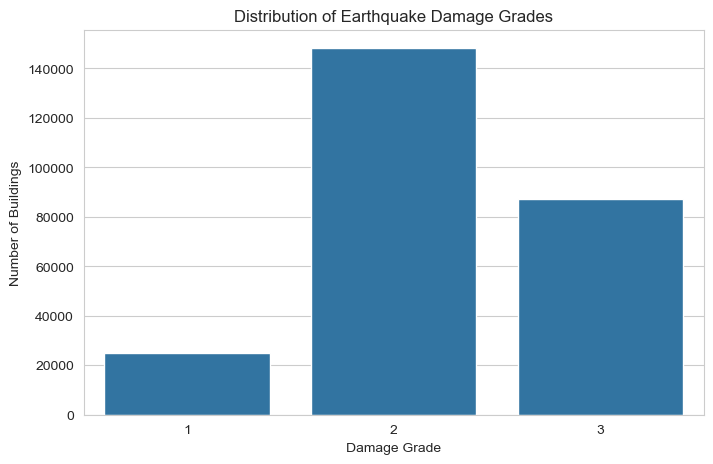

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(data=data, x='damage_grade')

plt.title('Distribution of Earthquake Damage Grades')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Buildings')

plt.show()

In [79]:
# Separate independent variables (features)

X = data.drop(
    columns=['building_id', 'damage_grade', 'age_group', 'floor_group']
)

print("Features Dataset Shape:", X.shape)
print("\nFeature Columns:")
print(X.columns.tolist())

Features Dataset Shape: (260601, 38)

Feature Columns:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_go

In [80]:
# Separate dependent variable (target)

y = data['damage_grade']

print("Target Dataset Shape:", y.shape)
print("\nTarget Classes:")
print(y.value_counts().sort_index())

Target Dataset Shape: (260601,)

Target Classes:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


In [81]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nMissing Values in X:", X.isnull().sum().sum())
print("Missing Values in y:", y.isnull().sum())

X Shape: (260601, 38)
y Shape: (260601,)

Missing Values in X: 0
Missing Values in y: 0


In [82]:
from sklearn.model_selection import train_test_split

In [83]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [84]:
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (208480, 38)
Testing Features Shape: (52121, 38)

Training Target Shape: (208480,)
Testing Target Shape: (52121,)


In [85]:
print("Training Target Distribution:")
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))

Training Target Distribution:
damage_grade
1    9.64
2   56.89
3   33.47
Name: proportion, dtype: float64

Testing Target Distribution:
damage_grade
1    9.64
2   56.89
3   33.47
Name: proportion, dtype: float64


In [86]:
# Numerical features
numerical_features = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families'
]

print("Numerical Features:")
print(numerical_features)

print("\nNumber of Numerical Features:", len(numerical_features))

Numerical Features:
['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

Number of Numerical Features: 5


In [87]:
# Categorical features
categorical_features = [
    'geo_level_1_id',
    'geo_level_2_id',
    'geo_level_3_id',
    'land_surface_condition',
    'foundation_type',
    'roof_type',
    'ground_floor_type',
    'other_floor_type',
    'position',
    'plan_configuration',
    'legal_ownership_status'
]

print("Categorical Features:")
print(categorical_features)

print("\nNumber of Categorical Features:", len(categorical_features))

Categorical Features:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Number of Categorical Features: 11


In [88]:
# Binary features
binary_features = [
    col for col in X.columns
    if X[col].nunique() == 2
]

print("Binary Features:")
print(binary_features)

print("\nNumber of Binary Features:", len(binary_features))

Binary Features:
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']

Number of Binary Features: 22


In [89]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [90]:
# Numerical features
numerical_features = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families'
]

# Categorical features
categorical_features = [
    'geo_level_1_id',
    'geo_level_2_id',
    'geo_level_3_id',
    'land_surface_condition',
    'foundation_type',
    'roof_type',
    'ground_floor_type',
    'other_floor_type',
    'position',
    'plan_configuration',
    'legal_ownership_status'
]

# Binary features
binary_features = [
    col for col in X.columns
    if X[col].nunique() == 2
]

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Binary Features:", len(binary_features))

Numerical Features: 5
Categorical Features: 11
Binary Features: 22


In [91]:
numerical_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

In [92]:
categorical_transformer = Pipeline(
    steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [93]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)

In [94]:
print("Preprocessing Pipeline:")
print(preprocessor)

Preprocessing Pipeline:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['count_floors_pre_eq', 'age',
                                  'area_percentage', 'height_percentage',
                                  'count_families']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['geo_level_1_id', 'geo_level_2_id',
                                  'geo_level_3_id', 'land_surface_condition',
                                  'foundation_type', 'roof_typ...
                                  'has_superstructure_rc_engineered',
                                  'has_superstructure_other',
                                  'has_secondary_use',
                                  'has_secondary_use_agriculture',
  

In [95]:
# Fit preprocessing pipeline on training data
X_train_processed = preprocessor.fit_transform(X_train)

print("Training Data Preprocessing Completed!")
print("Processed Training Shape:", X_train_processed.shape)

Training Data Preprocessing Completed!
Processed Training Shape: (208480, 12885)


In [96]:
# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Testing Data Preprocessing Completed!")
print("Processed Testing Shape:", X_test_processed.shape)

Testing Data Preprocessing Completed!
Processed Testing Shape: (52121, 12885)


In [97]:
print("Training Data Type:", type(X_train_processed))
print("Testing Data Type:", type(X_test_processed))

print("\nTraining Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Type: <class 'scipy.sparse._csr.csr_matrix'>
Testing Data Type: <class 'scipy.sparse._csr.csr_matrix'>

Training Data Shape: (208480, 12885)
Testing Data Shape: (52121, 12885)

Training Target Shape: (208480,)
Testing Target Shape: (52121,)


In [98]:
# Calculate memory usage of processed datasets

from scipy.sparse import issparse

def calculate_memory_usage(data):
    if issparse(data):
        memory_bytes = (
            data.data.nbytes +
            data.indices.nbytes +
            data.indptr.nbytes
        )
    else:
        memory_bytes = data.nbytes

    return memory_bytes / (1024 ** 2)


training_memory = calculate_memory_usage(X_train_processed)
testing_memory = calculate_memory_usage(X_test_processed)

print("Training Data Memory Usage:",
      round(training_memory, 2), "MB")

print("Testing Data Memory Usage:",
      round(testing_memory, 2), "MB")

print("Total Memory Usage:",
      round(training_memory + testing_memory, 2), "MB")

Training Data Memory Usage: 42.99 MB
Testing Data Memory Usage: 10.75 MB
Total Memory Usage: 53.74 MB


In [99]:
print("Original Feature Count:", X_train.shape[1])
print("Processed Feature Count:", X_train_processed.shape[1])

Original Feature Count: 38
Processed Feature Count: 12885


In [100]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [101]:
# Create baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Train model
baseline_model.fit(X_train_processed, y_train)

print("Baseline Model Training Completed!")

Baseline Model Training Completed!


In [102]:
# Predict on test data
y_pred_baseline = baseline_model.predict(X_test_processed)

print("Baseline Predictions:")
print(y_pred_baseline[:20])

Baseline Predictions:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [103]:
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy Percentage:", round(baseline_accuracy * 100, 2), "%")

Baseline Accuracy: 0.5689
Baseline Accuracy Percentage: 56.89 %


In [104]:
print("Baseline Classification Report:")
print(classification_report(y_test, y_pred_baseline))

Baseline Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00      5025
           2       0.57      1.00      0.73     29652
           3       0.00      0.00      0.00     17444

    accuracy                           0.57     52121
   macro avg       0.19      0.33      0.24     52121
weighted avg       0.32      0.57      0.41     52121



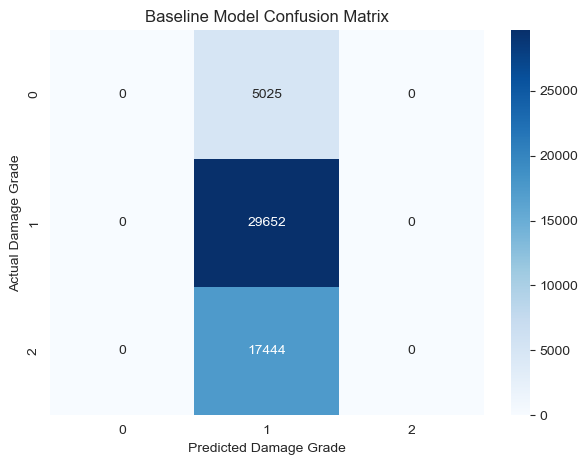

In [105]:
cm_baseline = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Baseline Model Confusion Matrix')
plt.xlabel('Predicted Damage Grade')
plt.ylabel('Actual Damage Grade')

plt.show()

In [106]:
from sklearn.tree import DecisionTreeClassifier

In [107]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=50,
    max_features='sqrt',
    random_state=42,
    class_weight='balanced'
)

print("Decision Tree Model Initialized!")

Decision Tree Model Initialized!


In [108]:
from sklearn.model_selection import train_test_split

# Select a representative training sample
sample_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=50000,
    stratify=y_train,
    random_state=42
)

X_train_sample = X_train_processed[sample_indices]
y_train_sample = y_train.iloc[sample_indices]

print("Sample Training Shape:", X_train_sample.shape)
print("Sample Target Shape:", y_train_sample.shape)

Sample Training Shape: (50000, 12885)
Sample Target Shape: (50000,)


In [109]:
decision_tree_model.fit(X_train_sample, y_train_sample)

print("Decision Tree Model Training Completed!")

Decision Tree Model Training Completed!


In [110]:
y_pred_dt = decision_tree_model.predict(X_test_processed)

print("Decision Tree Predictions Generated!")
print("\nFirst 20 Predictions:")
print(y_pred_dt[:20])

Decision Tree Predictions Generated!

First 20 Predictions:
[2 1 3 2 3 3 3 1 3 3 3 3 3 1 2 3 3 3 3 3]


In [111]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy, 4))
print("Decision Tree Accuracy Percentage:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 0.3503
Decision Tree Accuracy Percentage: 35.03 %


In [112]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           1       0.18      0.46      0.25      5025
           2       0.65      0.15      0.25     29652
           3       0.36      0.66      0.46     17444

    accuracy                           0.35     52121
   macro avg       0.39      0.42      0.32     52121
weighted avg       0.51      0.35      0.32     52121



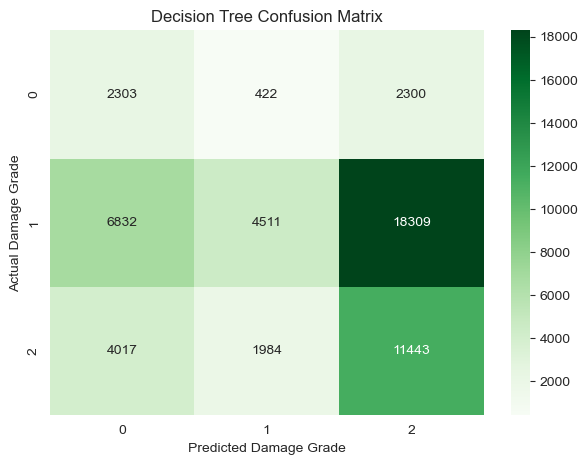

In [113]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Damage Grade')
plt.ylabel('Actual Damage Grade')

plt.show()

In [114]:
from sklearn.ensemble import RandomForestClassifier

In [115]:
rf_sample_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=20000,
    stratify=y_train,
    random_state=42
)

X_train_rf = X_train_processed[rf_sample_indices]
y_train_rf = y_train.iloc[rf_sample_indices]

print("Random Forest Training Shape:", X_train_rf.shape)
print("Target Shape:", y_train_rf.shape)

Random Forest Training Shape: (20000, 12885)
Target Shape: (20000,)


In [116]:
random_forest_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=12,
    min_samples_leaf=20,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Random Forest Model Initialized!")

Random Forest Model Initialized!


In [117]:
random_forest_model.fit(X_train_rf, y_train_rf)

,n_estimators,50
,criterion,'gini'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,20
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [118]:
y_pred_rf = random_forest_model.predict(X_test_processed)

In [119]:
print("Random Forest predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))
print("First 10 predictions:", y_pred_rf[:10])

Random Forest predictions generated successfully!
Number of predictions: 52121
First 10 predictions: [3 1 1 1 3 3 3 1 3 2]


## 6. Model Evaluation and Comparison

In this section, we compare the performance of the baseline, Decision Tree, and Random Forest classifiers using evaluation metrics such as accuracy, precision, recall, and F1-score.

In [120]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision (Weighted)': [
        precision_score(y_test, y_pred_baseline, average='weighted'),
        precision_score(y_test, y_pred_dt, average='weighted'),
        precision_score(y_test, y_pred_rf, average='weighted')
    ],
    'Recall (Weighted)': [
        recall_score(y_test, y_pred_baseline, average='weighted'),
        recall_score(y_test, y_pred_dt, average='weighted'),
        recall_score(y_test, y_pred_rf, average='weighted')
    ],
    'F1-Score (Weighted)': [
        f1_score(y_test, y_pred_baseline, average='weighted'),
        f1_score(y_test, y_pred_dt, average='weighted'),
        f1_score(y_test, y_pred_rf, average='weighted')
    ],
    'F1-Score (Macro)': [
        f1_score(y_test, y_pred_baseline, average='macro'),
        f1_score(y_test, y_pred_dt, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro')
    ]
})

model_comparison

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),F1-Score (Macro)
0,Baseline,0.57,0.32,0.57,0.41,0.24
1,Decision Tree,0.35,0.51,0.35,0.32,0.32
2,Random Forest,0.47,0.60,0.47,0.45,0.46


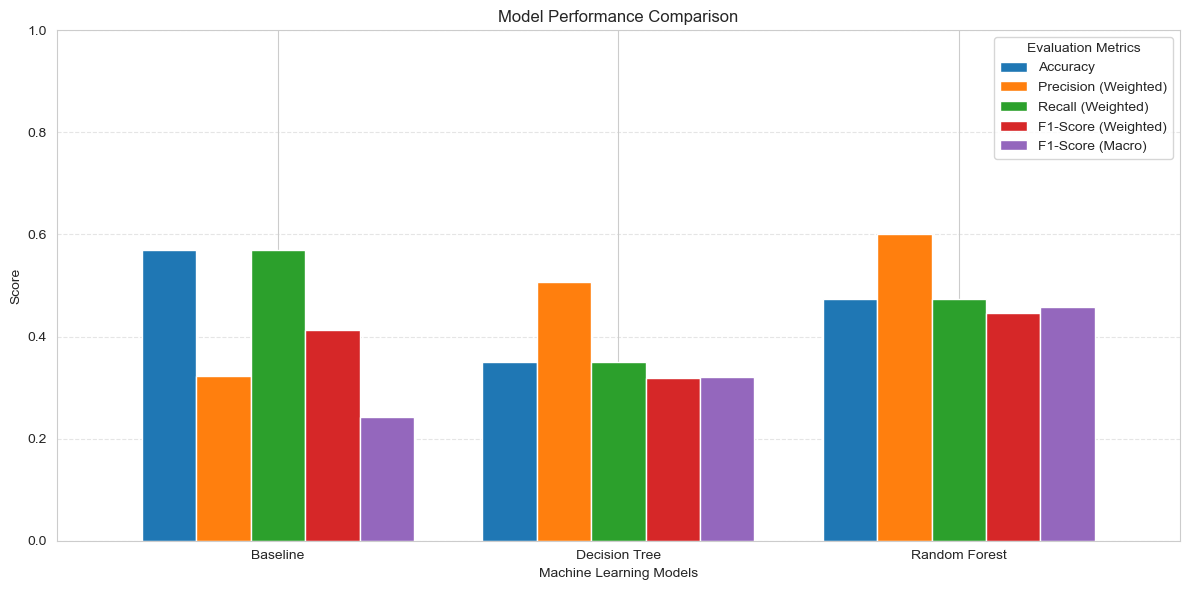

In [121]:
model_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 6.1 Confusion Matrix Analysis

Confusion matrices are used to evaluate the classification performance of each model by comparing actual damage grades with predicted damage grades. They help identify correctly classified instances and misclassifications across the three damage categories.

This analysis provides a better understanding of the models' ability to distinguish between low, medium, and severe earthquake damage.

In [122]:
from sklearn.metrics import confusion_matrix

In [123]:
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Baseline Confusion Matrix:")
print(cm_baseline)

print("\nDecision Tree Confusion Matrix:")
print(cm_dt)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

Baseline Confusion Matrix:
[[    0  5025     0]
 [    0 29652     0]
 [    0 17444     0]]

Decision Tree Confusion Matrix:
[[ 2303   422  2300]
 [ 6832  4511 18309]
 [ 4017  1984 11443]]

Random Forest Confusion Matrix:
[[ 3627   673   725]
 [ 6909  7442 15301]
 [ 1780  2014 13650]]


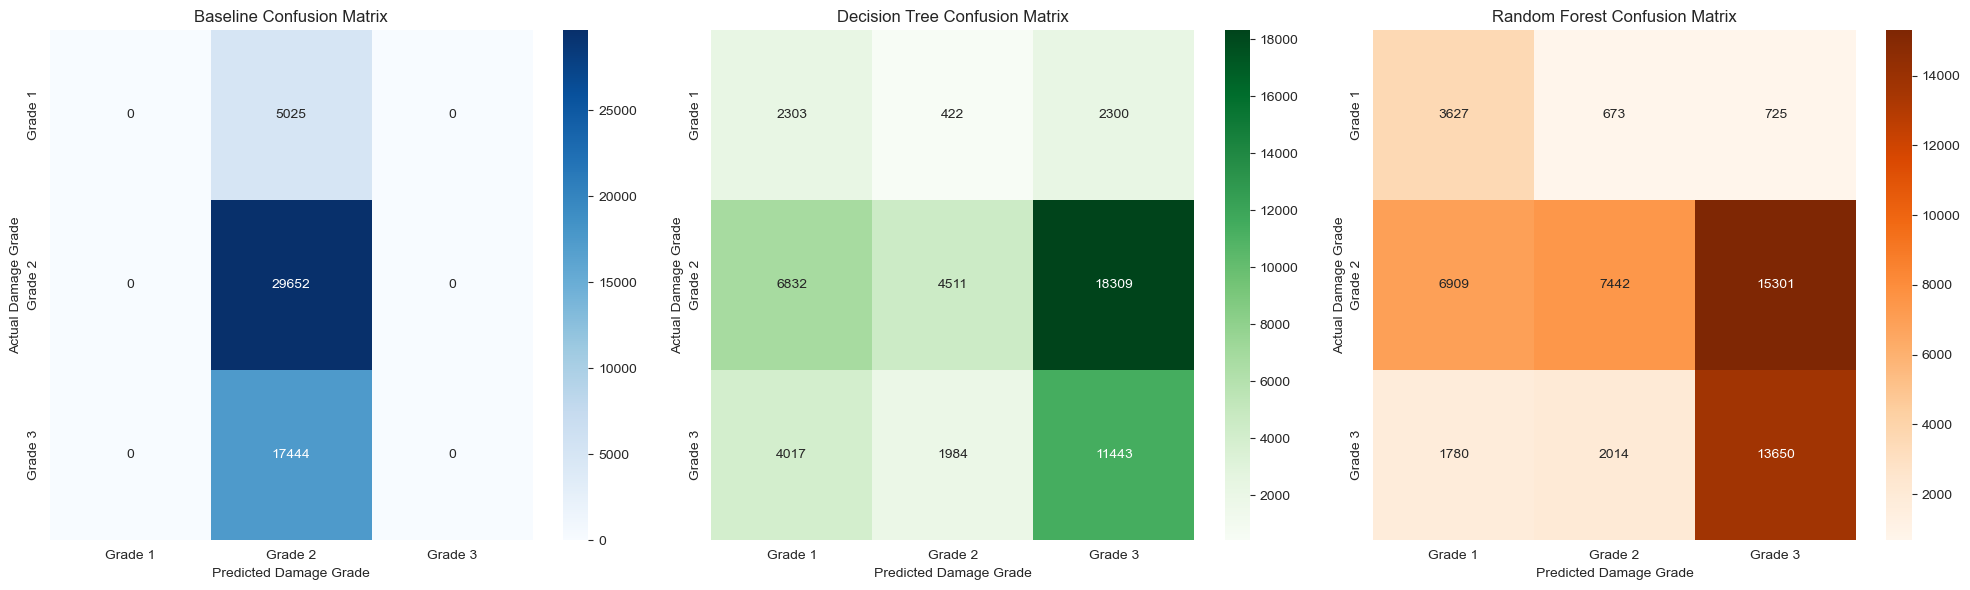

In [124]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

labels = ['Grade 1', 'Grade 2', 'Grade 3']

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)
axes[0].set_title('Baseline Confusion Matrix')
axes[0].set_xlabel('Predicted Damage Grade')
axes[0].set_ylabel('Actual Damage Grade')

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted Damage Grade')
axes[1].set_ylabel('Actual Damage Grade')

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[2]
)
axes[2].set_title('Random Forest Confusion Matrix')
axes[2].set_xlabel('Predicted Damage Grade')
axes[2].set_ylabel('Actual Damage Grade')

plt.tight_layout()
plt.show()

### 6.2 Classification Report Analysis

Classification reports provide a detailed evaluation of model performance for each damage grade using precision, recall, and F1-score.

These metrics help assess whether the models can reliably identify buildings belonging to different damage categories, particularly severe damage, which is important for earthquake damage assessment and disaster mitigation planning.

In [125]:
# Classification Report Analysis

from sklearn.metrics import classification_report

# Generate classification reports for all models
baseline_report = classification_report(
    y_test, y_pred_baseline,
    output_dict=True,
    zero_division=0
)

decision_tree_report = classification_report(
    y_test, y_pred_dt,
    output_dict=True,
    zero_division=0
)

random_forest_report = classification_report(
    y_test, y_pred_rf,
    output_dict=True,
    zero_division=0
)

# Compare F1 Scores
model_f1_comparison = pd.DataFrame({
    'Model': ['Baseline', 'Decision Tree', 'Random Forest'],
    'Macro F1 Score': [
        baseline_report['macro avg']['f1-score'],
        decision_tree_report['macro avg']['f1-score'],
        random_forest_report['macro avg']['f1-score']
    ],
    'Weighted F1 Score': [
        baseline_report['weighted avg']['f1-score'],
        decision_tree_report['weighted avg']['f1-score'],
        random_forest_report['weighted avg']['f1-score']
    ]
})

print("Classification Report Comparison")
display(model_f1_comparison.round(3))

Classification Report Comparison


,Model,Macro F1 Score,Weighted F1 Score
0,Baseline,0.24,0.41
1,Decision Tree,0.32,0.32
2,Random Forest,0.46,0.45


### Classification Report Analysis – Key Findings

1. **Baseline Model:** The baseline model achieved a macro F1-score of 0.24 and weighted F1-score of 0.41. It predominantly predicts Damage Grade 2 and performs poorly in identifying the other damage categories.

2. **Decision Tree:** The Decision Tree achieved a macro F1-score of 0.32 and weighted F1-score of 0.32. It identifies different damage categories but demonstrates limited overall predictive performance.

3. **Random Forest:** The Random Forest achieved the highest macro F1-score of 0.46 and weighted F1-score of 0.45 among the evaluated models.

4. **Class Imbalance:** The models demonstrate varying performance across damage grades, highlighting the challenges associated with the imbalanced target distribution.

5. **Model Comparison:** Random Forest provides the best balance of classification performance across the three damage categories compared with the Baseline and Decision Tree models.

**Conclusion:** Based on the classification report, Random Forest is the best-performing model among the three evaluated models.

## 7. Feature Importance Analysis

Feature importance analysis helps identify the building characteristics and geographical factors that contribute most to earthquake damage prediction.

The Random Forest model is used to evaluate feature importance based on the contribution of individual features to the model's predictive decisions. This analysis helps identify important structural characteristics and provides insights that may support earthquake-resistant construction and disaster risk reduction strategies.

In [126]:
feature_importance = random_forest_model.feature_importances_

print("Number of feature importance values:", len(feature_importance))
print("Number of processed features:", X_train_rf.shape[1])

Number of feature importance values: 12885
Number of processed features: 12885


In [127]:
feature_names = preprocessor.get_feature_names_out()

print("Total feature names:", len(feature_names))
print("First 20 feature names:")
print(feature_names[:20])

Total feature names: 12885
First 20 feature names:
['num__count_floors_pre_eq' 'num__age' 'num__area_percentage'
 'num__height_percentage' 'num__count_families' 'cat__geo_level_1_id_0'
 'cat__geo_level_1_id_1' 'cat__geo_level_1_id_2' 'cat__geo_level_1_id_3'
 'cat__geo_level_1_id_4' 'cat__geo_level_1_id_5' 'cat__geo_level_1_id_6'
 'cat__geo_level_1_id_7' 'cat__geo_level_1_id_8' 'cat__geo_level_1_id_9'
 'cat__geo_level_1_id_10' 'cat__geo_level_1_id_11'
 'cat__geo_level_1_id_12' 'cat__geo_level_1_id_13'
 'cat__geo_level_1_id_14']


In [128]:
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(20)

,Feature,Importance
0,cat__ground_floor_type_f,0.07
1,cat__foundation_type_r,0.06
2,cat__roof_type_x,0.05
3,cat__geo_level_1_id_17,0.04
4,cat__geo_level_1_id_13,0.04
5,cat__geo_level_2_id_36,0.03
6,cat__other_floor_type_j,0.03
7,bin__has_superstructure_cement_mortar_brick,0.03
8,num__count_floors_pre_eq,0.03
9,cat__other_floor_type_q,0.03


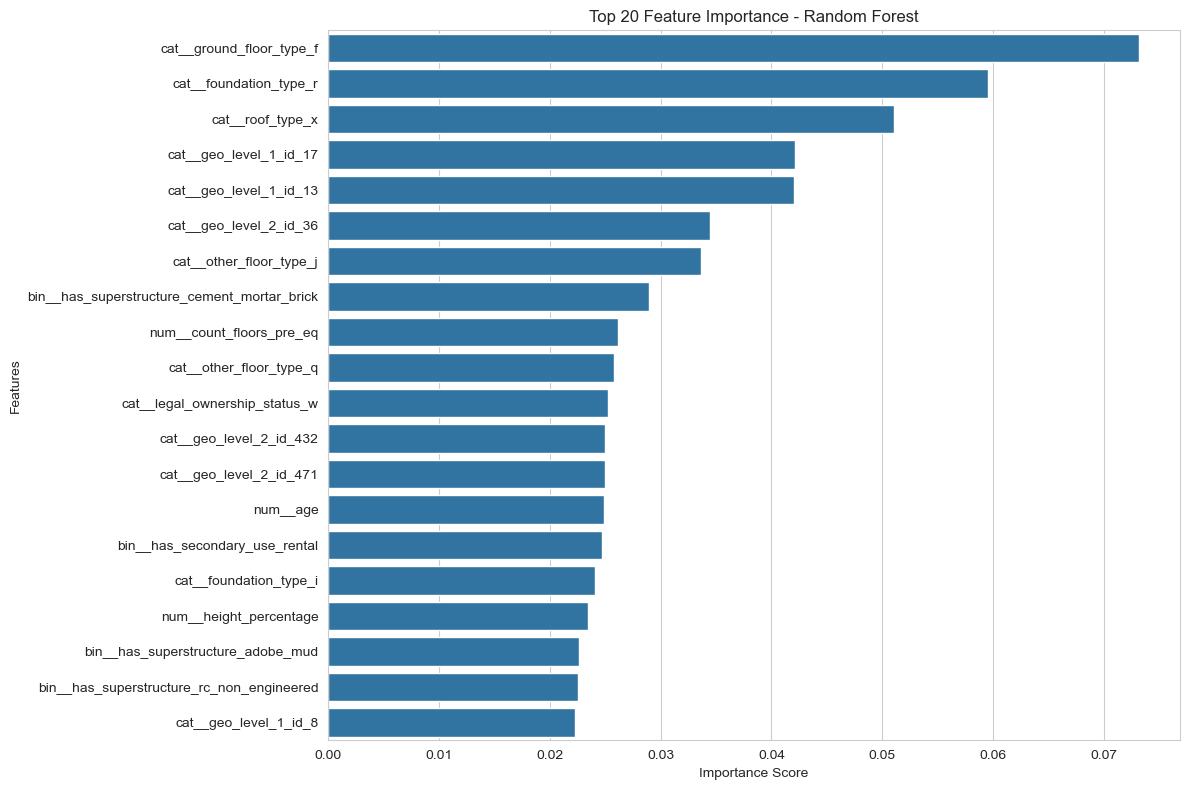

In [129]:
top_20_features = feature_importance_df.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Model Recommendation

Based on the evaluation of Baseline, Decision Tree, and Random Forest models, the Random Forest model is recommended as the best-performing model for this earthquake damage prediction project.

### Reasons for Recommendation

- **Better Overall Performance:** Random Forest achieved the highest Macro F1-score (0.46) and Weighted F1-score (0.45) among the evaluated models.
- **Improved Classification:** It demonstrates better classification performance across the three damage grades compared with the Baseline and Decision Tree models.
- **Feature Importance:** The model identifies important building characteristics and structural features that contribute to earthquake damage prediction.
- **Robustness:** Random Forest combines multiple decision trees, helping improve prediction stability compared with a single Decision Tree.

### Limitations

The model was trained on a subset of the dataset to manage computational requirements. Its current performance is not sufficient for real-world deployment in earthquake response or structural safety assessment.

Further improvements in model performance, validation on independent geographical regions, and domain expert evaluation are required before practical deployment.

**Final Recommendation:** Random Forest is selected as the best-performing model for further experimentation and improvement within this project.


## Challenges and Limitations

### 1. Class Imbalance
The target variable `damage_grade` contains an unequal distribution of observations across the three damage categories. This imbalance can affect model performance, particularly for underrepresented classes.

**Technique used:** Stratified train-test splitting and class-weight balancing in the Random Forest model.

**Reason:** These techniques help maintain class proportions and improve the model's ability to learn from different damage categories.

### 2. High-Dimensional Data
Categorical features, particularly geographical identifiers, generated a large number of features during One-Hot Encoding.

**Technique used:** Sparse matrix representation through OneHotEncoder.

**Reason:** Sparse matrices reduce memory consumption by storing only non-zero values, making high-dimensional data more manageable.

### 3. Computational Complexity
Training machine-learning models on a large dataset containing 260,601 building records required considerable computational resources.

**Technique used:** Sampling training data for Decision Tree and Random Forest models.

**Reason:** Sampling reduces training time and memory requirements while allowing model comparison.

### 4. Model Performance Limitations
The Random Forest model achieved a Macro F1-score of 0.46, indicating that predictive performance across the damage categories still requires improvement.

**Technique used:** Evaluation using Accuracy, Precision, Recall, F1-score, Classification Reports, and Confusion Matrices.

**Reason:** Multiple evaluation metrics provide a more comprehensive understanding of model performance, particularly when the target classes are imbalanced.

### 5. Geographical Generalization
Building characteristics and earthquake vulnerability can vary across geographical regions. The model may not generalize equally well to locations that were not adequately represented during training.

**Limitation:** Further validation using geographically independent datasets is required before real-world application.


## Earthquake Damage Mitigation Recommendations

Based on the analysis of building characteristics and predicted earthquake damage grades, the following recommendations can help reduce building vulnerability and improve earthquake preparedness.

### 1. Improve Structural Design
Buildings should be designed and constructed according to earthquake-resistant building codes. Structural components such as columns, beams, foundations, and connections should be designed to withstand seismic forces.

### 2. Strengthen Vulnerable Buildings
Buildings with vulnerable structural materials, weak foundations, and inadequate structural systems should undergo professional structural assessment and retrofitting where necessary.

### 3. Use Appropriate Construction Materials
The use of quality construction materials, proper reinforcement, and suitable construction techniques can improve building strength and reduce the risk of severe earthquake damage.

### 4. Prioritize High-Risk Buildings
Buildings identified as potentially vulnerable through damage assessment should be prioritized for detailed structural inspection, safety evaluation, and strengthening measures.

### 5. Improve Community Preparedness
Earthquake awareness programs, emergency evacuation planning, regular safety drills, and public education can help communities respond effectively during earthquakes.

### 6. Follow Building Regulations
Compliance with local building codes, construction standards, and safety regulations is essential for reducing earthquake-related structural damage and protecting lives.

**Note:** Machine-learning predictions should not replace professional structural engineering inspections or official building safety assessments.


## Conclusion

This project developed a machine-learning framework for predicting earthquake damage grades to buildings using structural, geographical, and building-related characteristics.

The analysis included data cleaning, exploratory data analysis, feature engineering, preprocessing, model training, and evaluation.

Three models were evaluated: Baseline, Decision Tree, and Random Forest.

The Random Forest model achieved the best overall performance, with a Macro F1-score of 0.46, Weighted F1-score of 0.45, and Accuracy of approximately 47%.

The project demonstrated the importance of feature preprocessing, handling class imbalance, model comparison, and evaluation using multiple performance metrics.

Although Random Forest performed better than the other evaluated models, its predictive performance requires further improvement before practical application. Future work could include hyperparameter tuning, advanced ensemble techniques, additional feature engineering, and geographical validation.

Overall, this project provides a foundation for data-driven earthquake damage prediction and highlights the potential of machine learning to support building vulnerability assessment and disaster risk management.
